<a href="https://colab.research.google.com/github/k10-j/API_summative/blob/main/Task1A_Task1B_Electricity_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Formative 1: Building a Pipeline for Time Series Data
## Task 1A: Understanding the Dataset & Task 1B: Analytical Questions

**Dataset:** Electricity Consumption and Production  
**Main target:** `Consumption`  
**Time column:** `DateTime`  
**Scope of this notebook:** Dataset understanding, data-quality checks, exploratory analysis, feature engineering, and at least five analytical questions.

## 1. Problem definition and dataset justification

Electricity demand changes over time. Understanding its temporal patterns can help describe periods of high and low demand and provide a foundation for forecasting future consumption.

In this notebook, we will explore historical electricity consumption alongside total production and generation-source measurements. The proposed forecasting target for the group's later modeling task is **`Consumption`**.

### Why this dataset is suitable
- It contains a timestamp column (`DateTime`) and a numerical target (`Consumption`).
- It includes additional measurements such as `Production`, `Wind`, `Solar`, `Coal`, and `Hydroelectric`.
- The time series can be explored using trends, time-of-day patterns, lagged values, and moving averages.
- Timestamped records can later be stored in a relational database and a document database and served through an API.

### Dataset source
Kaggle: [Electricity dataset](https://www.kaggle.com/datasets/mayuringle8890/electricity)


## 2. Learning objectives

By the end of Task 1A and 1B, this notebook should:
1. Describe the dataset's size, columns, time range, and observation frequency.
2. Check missing values, exact duplicate rows, duplicate timestamps, and suspicious values.
3. Summarize numerical variables and visualize their distributions.
4. Explore consumption over time and by calendar periods.
5. Answer at least five analytical questions, each with a visualization and interpretation.
6. Create and explain lagged and moving-average features without using future observations.

## 3. Import libraries

We use **pandas** for data handling, **NumPy** for numerical operations, and **Matplotlib** for visualizations.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Libraries imported successfully.")

Libraries imported successfully.



## 4. Load the Dataset from Google Drive

The dataset is stored in Google Drive so it can be accessed
whenever the notebook is reopened. We mount Google Drive
and read the CSV directly from its project folder.

In [ ]:
from google.colab import drive
import pandas as pd
from pathlib import Path

# Connect Google Drive to Colab
drive.mount('/content/drive')

# Path to the dataset stored in Google Drive
# Note: After mounting, the root of your Google Drive is under /content/drive/MyDrive/
DATA_PATH = Path(
    "/content/Electricity.csv"
)

# Check that the file exists
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        "Check the folder and filename in Google Drive."
    )

# Load the dataset
df_raw = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df_raw.shape)
display(df_raw.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully!
Shape: (46011, 10)


,DateTime,Consumption,Production,Nuclear,Wind,Hydroelectric,Oil and Gas,Coal,Solar,Biomass
0,2019-01-01 00:00:00,6352,6527,1395,79,1383,1896,1744,0,30
1,2019-01-01 01:00:00,6116,5701,1393,96,1112,1429,1641,0,30
2,2019-01-01 02:00:00,5873,5676,1393,142,1030,1465,1616,0,30
3,2019-01-01 03:00:00,5682,5603,1397,191,972,1455,1558,0,30
4,2019-01-01 04:00:00,5557,5454,1393,159,960,1454,1458,0,30


## 5. Understand the dataset structure

This section checks the column names, data types, and a small sample of the records. The timestamp should be parsed as a datetime value before time-based analysis.

In [ ]:
print("Column names:")
print(df_raw.columns.tolist())

print("\nData types before conversion:")
print(df_raw.dtypes)

print("\nRandom sample of 5 rows:")
display(df_raw.sample(min(5, len(df_raw)), random_state=42))

Column names:
['DateTime', 'Consumption', 'Production', 'Nuclear', 'Wind', 'Hydroelectric', 'Oil and Gas', 'Coal', 'Solar', 'Biomass']

Data types before conversion:
DateTime         object
Consumption       int64
Production        int64
Nuclear           int64
Wind              int64
Hydroelectric     int64
Oil and Gas       int64
Coal              int64
Solar             int64
Biomass           int64
dtype: object

Random sample of 5 rows:


,DateTime,Consumption,Production,Nuclear,Wind,Hydroelectric,Oil and Gas,Coal,Solar,Biomass
15854,2020-10-22 14:00:00,7009,6170,1384,515,2016,554,967,659,74
5159,2019-08-04 00:00:00,5558,6342,1344,1954,1033,375,1591,0,44
33445,2022-10-25 11:00:00,6791,6566,1377,169,2088,1327,1128,418,59
18729,2021-02-19 07:00:00,8808,8515,1400,618,3002,1828,1557,33,73
25018,2021-11-08 07:00:00,6736,5903,1412,65,1450,1517,1400,2,56


In [ ]:
required_columns = {"DateTime", "Consumption"}
missing_required = required_columns - set(df_raw.columns)

if missing_required:
    raise ValueError(f"Required column(s) not found: {sorted(missing_required)}")

df = df_raw.copy()
df["DateTime"] = pd.to_datetime(df["DateTime"], errors="coerce")

invalid_timestamps = df["DateTime"].isna().sum()
print(f"Invalid or unparseable timestamps: {invalid_timestamps}")

if invalid_timestamps:
    display(df.loc[df["DateTime"].isna()].head())

# Remove rows that have no usable timestamp, since time-series analysis requires one.
df = df.dropna(subset=["DateTime"]).copy()
df = df.sort_values("DateTime").reset_index(drop=True)

print("\nData types after timestamp conversion:")
print(df.dtypes)

Invalid or unparseable timestamps: 0

Data types after timestamp conversion:
DateTime         datetime64[ns]
Consumption               int64
Production                int64
Nuclear                   int64
Wind                      int64
Hydroelectric             int64
Oil and Gas               int64
Coal                      int64
Solar                     int64
Biomass                   int64
dtype: object


## 6. Time range and observation frequency

We calculate the earliest and latest timestamps, the number of unique timestamps, and the gaps between consecutive unique timestamps.

**Important limitation:** the `DateTime` column may not include a timezone. If it represents local time, daylight-saving-time transitions can create repeated or skipped clock times. We will report what the file shows and investigate timestamp duplicates rather than assuming that every repeated timestamp is an error.

In [ ]:
start_time = df["DateTime"].min()
end_time = df["DateTime"].max()
unique_times = pd.DatetimeIndex(df["DateTime"].drop_duplicates().sort_values())
time_diffs = unique_times.to_series().diff().dropna()

print(f"Start timestamp: {start_time}")
print(f"End timestamp:   {end_time}")
print(f"Calendar span:   {end_time - start_time}")
print(f"Rows with valid timestamps: {len(df):,}")
print(f"Unique timestamps: {df['DateTime'].nunique():,}")

print("\nMost common differences between unique timestamps:")
display(time_diffs.value_counts().head(10).rename_axis("Time difference").to_frame("Count"))

if not time_diffs.empty:
    print(f"Median interval between unique timestamps: {time_diffs.median()}")

Start timestamp: 2019-01-01 00:00:00
End timestamp:   2024-03-31 23:00:00
Calendar span:   1916 days 23:00:00
Rows with valid timestamps: 46,011
Unique timestamps: 46,002

Most common differences between unique timestamps:


,Count
Time difference,
0 days 01:00:00,45995
0 days 02:00:00,6


Median interval between unique timestamps: 0 days 01:00:00


## 7. Data-quality assessment

We check:
- missing values in each column;
- exact duplicate rows;
- repeated timestamps;
- numeric columns and their ranges;
- negative values in columns where negative measurements may be unexpected.

We will **not** automatically replace all unusual values or delete all repeated timestamps. First we measure the issue, then decide whether a transformation is justified and document it.

In [ ]:
missing_summary = (
    df.isna().sum()
      .rename("missing_count")
      .to_frame()
)
missing_summary["missing_percent"] = 100 * missing_summary["missing_count"] / len(df)
display(missing_summary)

exact_duplicate_count = int(df.duplicated().sum())
duplicate_timestamp_count = int(df["DateTime"].duplicated(keep=False).sum())
repeated_timestamp_excess = int(df["DateTime"].duplicated().sum())

print(f"Exact duplicate rows (beyond the first copy): {exact_duplicate_count}")
print(f"Rows belonging to a repeated timestamp group: {duplicate_timestamp_count}")
print(f"Extra rows caused by repeated timestamps: {repeated_timestamp_excess}")

print("\nExamples of repeated timestamps:")
display(
    df.loc[df["DateTime"].duplicated(keep=False)]
      .sort_values("DateTime")
      .head(20)
)

,missing_count,missing_percent
DateTime,0,0.00
Consumption,0,0.00
Production,0,0.00
Nuclear,0,0.00
Wind,0,0.00
Hydroelectric,0,0.00
Oil and Gas,0,0.00
Coal,0,0.00
Solar,0,0.00
Biomass,0,0.00


Exact duplicate rows (beyond the first copy): 4
Rows belonging to a repeated timestamp group: 14
Extra rows caused by repeated timestamps: 9

Examples of repeated timestamps:


,DateTime,Consumption,Production,Nuclear,Wind,Hydroelectric,Oil and Gas,Coal,Solar,Biomass
7178,2019-10-27 03:00:00,5186,4478,1373,77,750,696,1532,0,49
7179,2019-10-27 03:00:00,5196,4459,1373,74,725,719,1515,0,50
7180,2019-10-27 03:00:00,5196,4459,1373,74,725,719,1515,0,50
15915,2020-10-25 03:00:00,5220,5412,1418,1188,1098,594,1048,0,65
15916,2020-10-25 03:00:00,5181,5356,1417,1120,1155,566,1034,0,65
15917,2020-10-25 03:00:00,5220,5412,1418,1188,1098,594,1048,0,65
24820,2021-10-31 03:00:00,5351,5265,1414,108,961,1314,1411,0,56
24821,2021-10-31 03:00:00,5341,5258,1415,141,934,1314,1393,0,58
24822,2021-10-31 03:00:00,5341,5258,1415,141,934,1314,1393,0,58
33557,2022-10-30 03:00:00,4475,5266,1385,485,1375,904,1064,0,52


In [ ]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
print("Numeric columns:", numeric_cols)

print("\nNegative-value counts by numeric column:")
negative_counts = (df[numeric_cols] < 0).sum().sort_values(ascending=False)
display(negative_counts.rename("negative_count").to_frame())

print("\nNumeric summary statistics:")
display(df[numeric_cols].describe().T)

Numeric columns: ['Consumption', 'Production', 'Nuclear', 'Wind', 'Hydroelectric', 'Oil and Gas', 'Coal', 'Solar', 'Biomass']

Negative-value counts by numeric column:


,negative_count
Wind,499
Consumption,0
Production,0
Nuclear,0
Hydroelectric,0
Oil and Gas,0
Coal,0
Solar,0
Biomass,0



Numeric summary statistics:


,count,mean,std,min,25%,50%,75%,max
Consumption,"46,011.00","6,587.62","1,043.65","3,889.00","5,773.00","6,552.00","7,321.00","9,615.00"
Production,"46,011.00","6,518.65",986.81,"3,315.00","5,814.00","6,462.00","7,176.00","9,886.00"
Nuclear,"46,011.00","1,291.18",236.55,562.00,"1,347.00","1,383.00","1,405.00","1,457.00"
Wind,"46,011.00",792.31,675.81,-26.00,236.00,592.00,"1,205.00","2,811.00"
Hydroelectric,"46,011.00","1,857.05",692.59,175.00,"1,347.00","1,747.00","2,265.00","4,434.00"
Oil and Gas,"46,011.00","1,171.89",434.75,198.00,858.00,"1,211.00","1,511.00","2,141.00"
Coal,"46,011.00","1,193.16",320.45,279.00,962.00,"1,172.00","1,406.00","2,537.00"
Solar,"46,011.00",156.69,229.50,0.00,0.00,2.00,280.00,"1,137.00"
Biomass,"46,011.00",55.85,14.24,17.00,45.00,57.00,67.00,89.00


### Initial preprocessing decisions

Use the evidence from the cells above to make and document decisions:

1. **Missing values:** report counts first. If any are found, decide whether interpolation, forward filling, or dropping is appropriate for that variable and explain why. Do not fill values merely to make the table complete.
2. **Exact duplicate rows:** inspect them. If they are truly identical duplicate records, keeping one copy is usually reasonable; record the number removed.
3. **Repeated timestamps:** investigate before deleting. A repeated local clock time can occur at a daylight-saving-time transition. If the dataset has no timezone or offset information, the two records may not be distinguishable with certainty.
4. **Negative generation measurements:** inspect the affected rows and dataset documentation. Do not assume a negative value is an error without evidence.
5. **Outliers:** flag and investigate them. Do not remove valid peaks simply because they are far from the mean.

The original `df` is retained for traceability. Later cells create separate analysis tables where needed.

## 8. Numerical distributions

The summary table describes central tendency and spread. Histograms show each variable's distribution, while boxplots help identify extreme values. Because variables may have very different scales, the boxplots are drawn separately.

,count,mean,std,min,25%,50%,75%,max
Consumption,"46,011.00","6,587.62","1,043.65","3,889.00","5,773.00","6,552.00","7,321.00","9,615.00"
Production,"46,011.00","6,518.65",986.81,"3,315.00","5,814.00","6,462.00","7,176.00","9,886.00"
Nuclear,"46,011.00","1,291.18",236.55,562.00,"1,347.00","1,383.00","1,405.00","1,457.00"
Wind,"46,011.00",792.31,675.81,-26.00,236.00,592.00,"1,205.00","2,811.00"
Hydroelectric,"46,011.00","1,857.05",692.59,175.00,"1,347.00","1,747.00","2,265.00","4,434.00"
Oil and Gas,"46,011.00","1,171.89",434.75,198.00,858.00,"1,211.00","1,511.00","2,141.00"
Coal,"46,011.00","1,193.16",320.45,279.00,962.00,"1,172.00","1,406.00","2,537.00"
Solar,"46,011.00",156.69,229.50,0.00,0.00,2.00,280.00,"1,137.00"
Biomass,"46,011.00",55.85,14.24,17.00,45.00,57.00,67.00,89.00


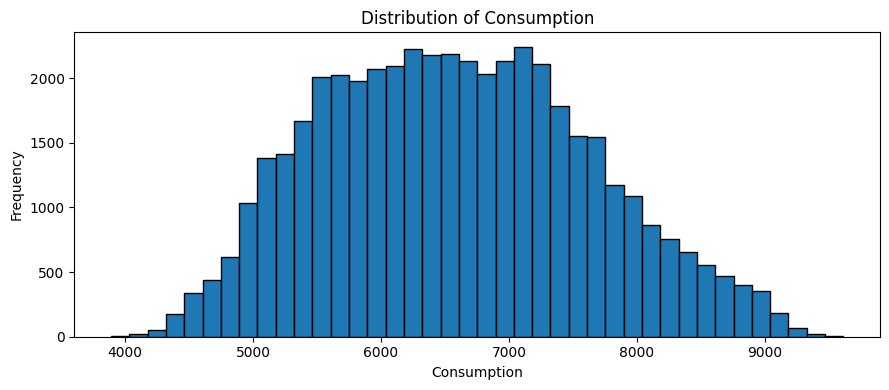

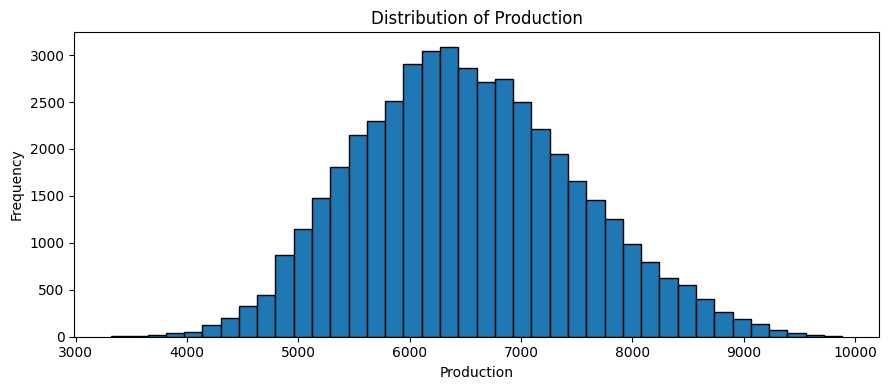

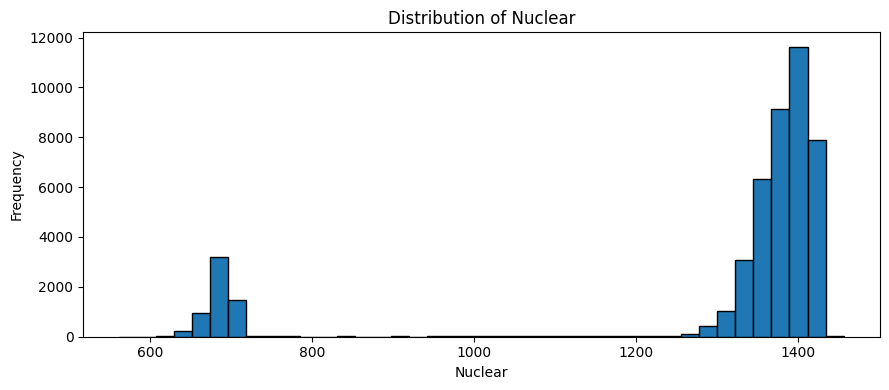

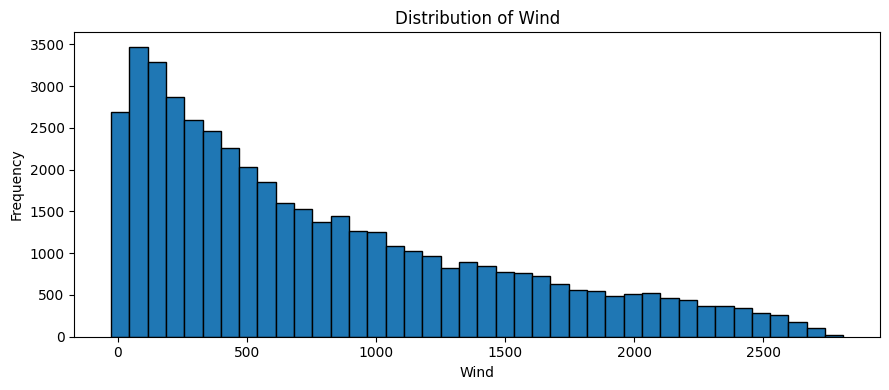

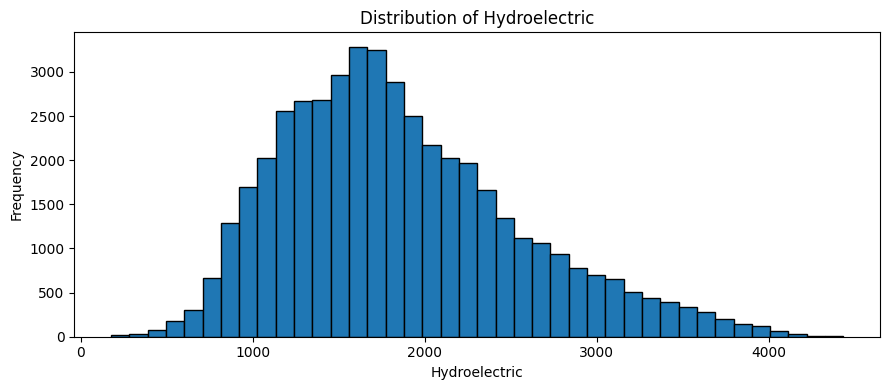

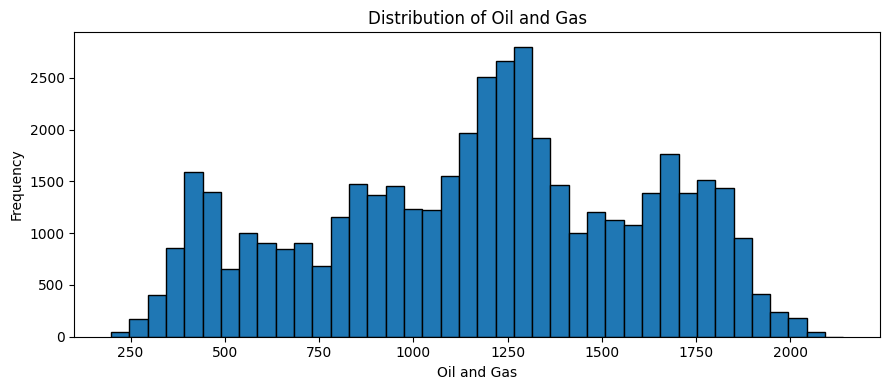

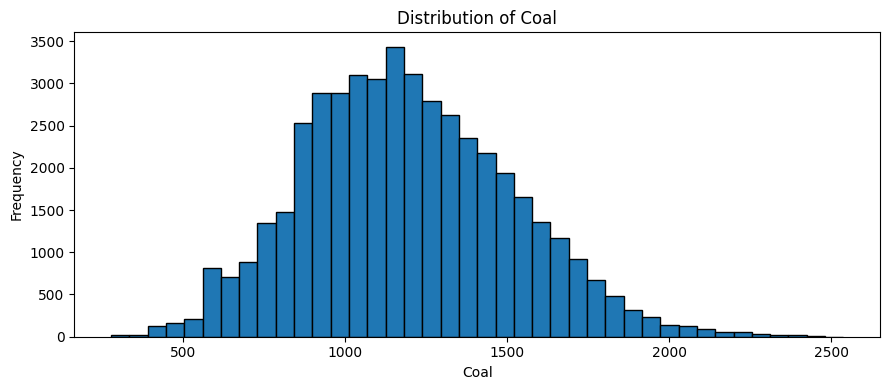

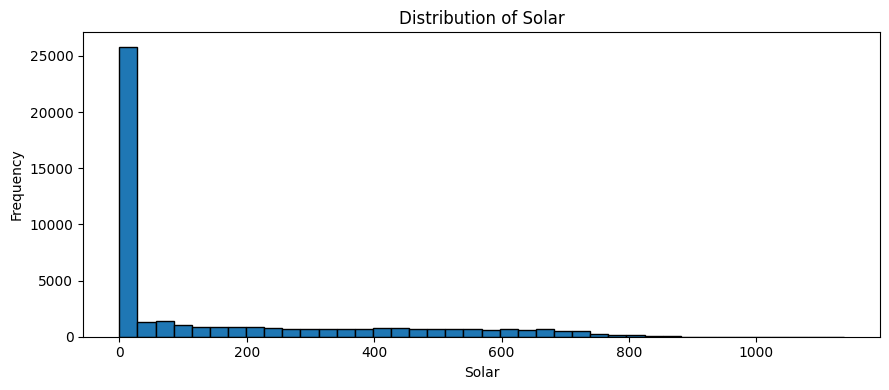

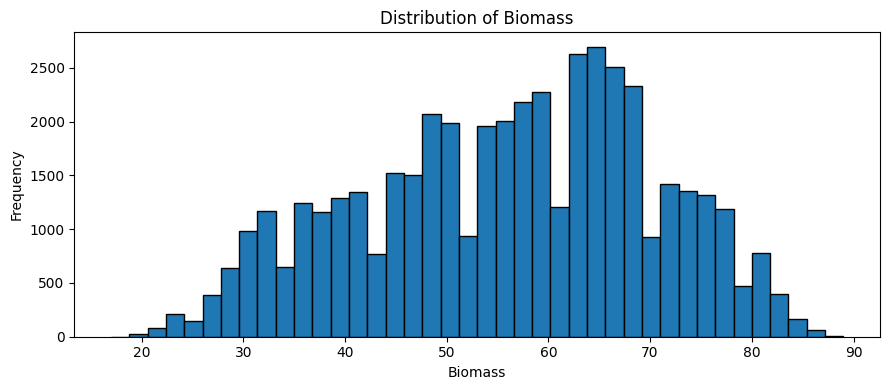

In [ ]:
display(df[numeric_cols].describe().T)

for col in numeric_cols:
    plt.figure(figsize=(9, 4))
    plt.hist(df[col].dropna(), bins=40, edgecolor="black")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

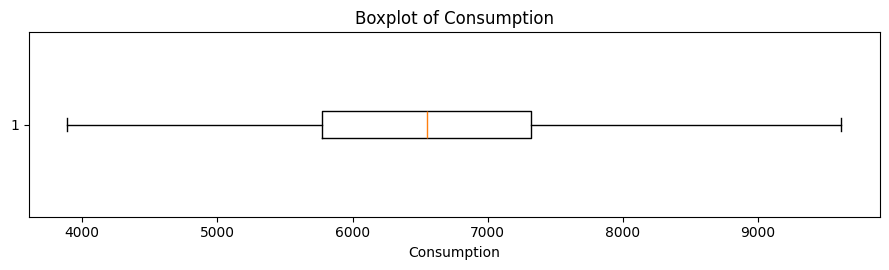

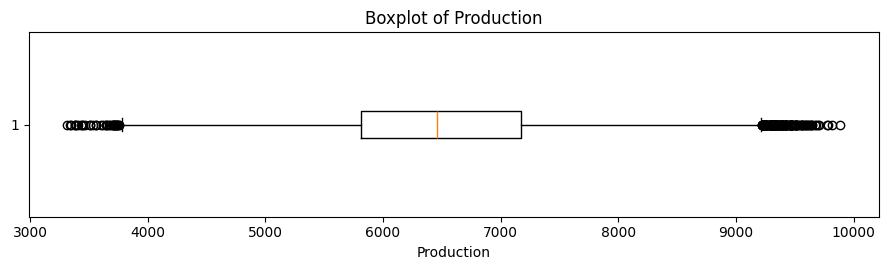

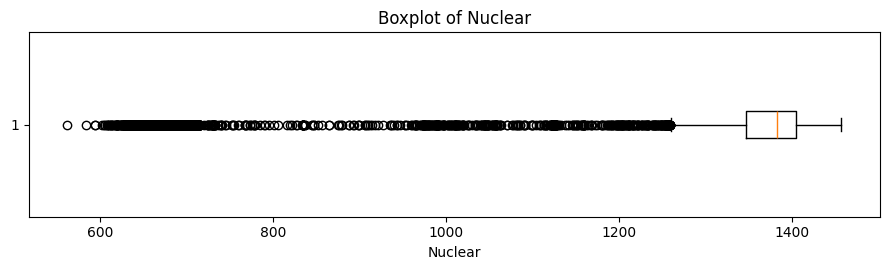

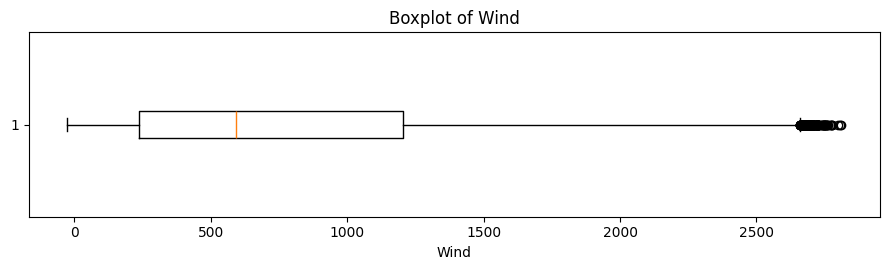

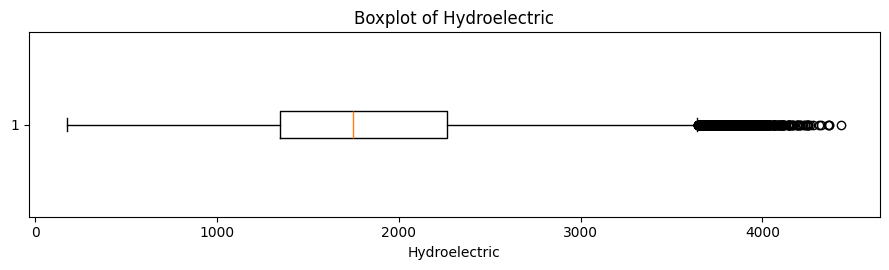

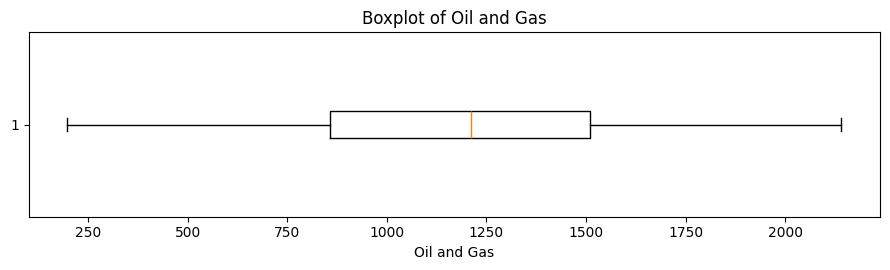

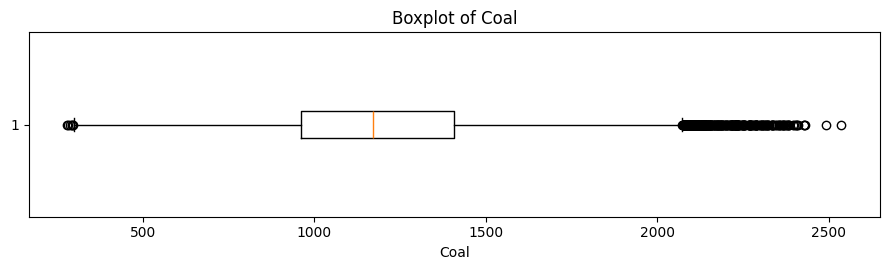

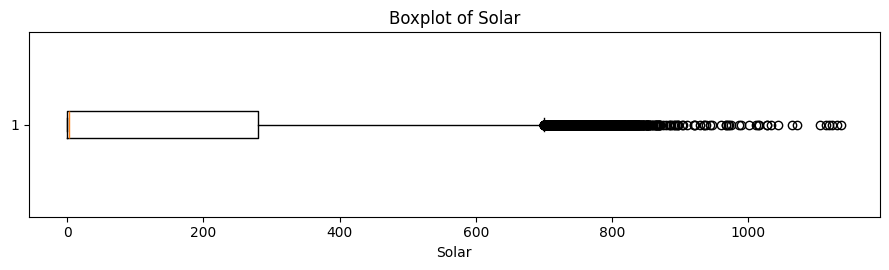

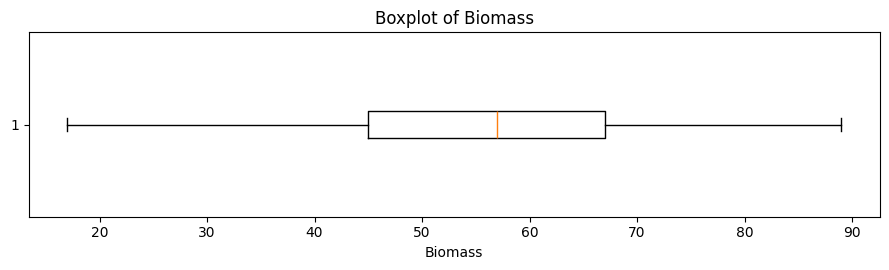

In [ ]:
for col in numeric_cols:
    plt.figure(figsize=(9, 2.8))
    plt.boxplot(df[col].dropna(), vert=False)
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

### Interpretation of Numerical Distributions

The numerical distributions show that electricity consumption and total production have similar typical values, with mean values of approximately 6,588 and 6,519, respectively. Their means are slightly higher than their medians, suggesting mildly right-skewed distributions. Both variables also show considerable variability, with standard deviations of approximately 1,044 for consumption and 987 for production.

Among the energy sources, nuclear and biomass generation appear more concentrated around their central values, while wind and hydroelectric generation show greater variability. Wind generation has a mean of approximately 792 and a median of 592, suggesting a right-skewed distribution with some periods of much higher output. Solar generation has a particularly noticeable pattern: its median is only 2, its first quartile is zero, and its mean is approximately 157. This suggests that many observations have very low or zero solar generation, while some periods have substantially higher output.

The boxplots also highlight observations that may be unusually high or low. For example, consumption ranges from 3,889 to 9,615, hydroelectric generation ranges from 175 to 4,434, and solar generation reaches 1,137. Wind generation also contains negative values, with a minimum of −26, which should be investigated to understand how these values were recorded. However, unusually high or low observations are not necessarily errors; they may represent genuine changes in electricity demand or generation.

Overall, the distributions reveal differences in the variability and behaviour of the electricity variables. These findings help identify patterns and observations that deserve further investigation before proceeding with additional time-series analysis. Any decisions to remove or modify unusual values should be based on further checks rather than the boxplots alone.

## 9. Overall electricity-consumption trend

### Analytical question 1
**How has electricity consumption changed over the recorded period?**

We plot the raw series and a daily mean series. The daily mean makes longer-term patterns easier to see without removing the underlying hourly variation from the dataset.

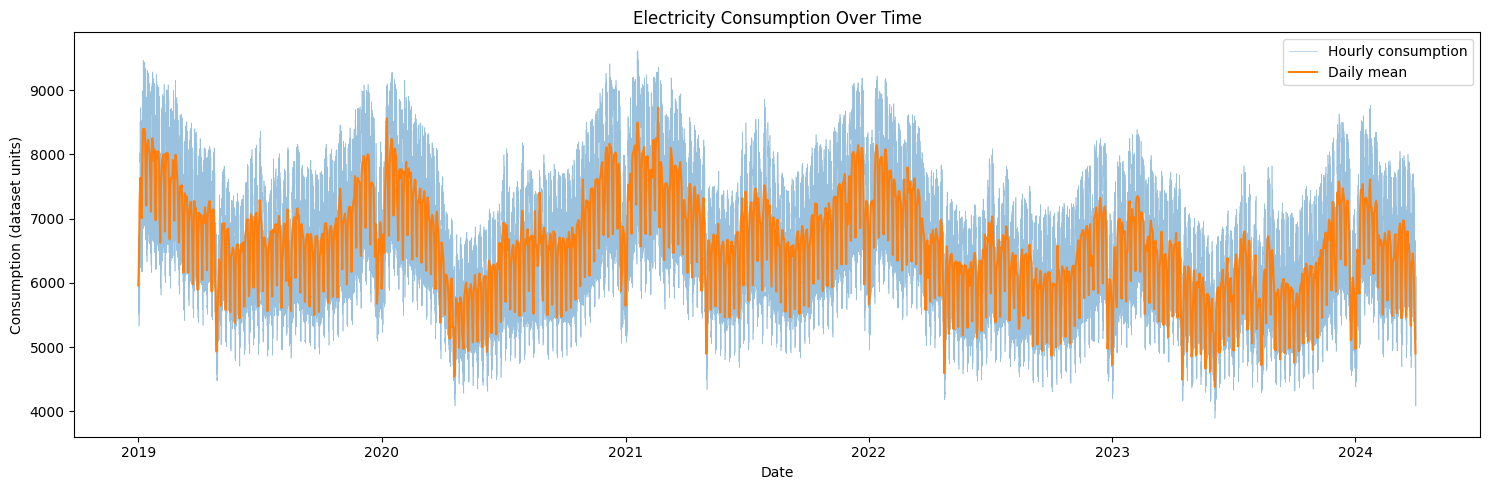

Consumption summary:


,count,mean,std,min,25%,50%,75%,max
Consumption,"46,011.00","6,587.62","1,043.65","3,889.00","5,773.00","6,552.00","7,321.00","9,615.00"


In [ ]:
consumption_daily = (
    df.set_index("DateTime")["Consumption"]
      .resample("D")
      .mean()
)

plt.figure(figsize=(15, 5))
plt.plot(df["DateTime"], df["Consumption"], linewidth=0.45, alpha=0.45, label="Hourly consumption")
plt.plot(consumption_daily.index, consumption_daily.values, linewidth=1.5, label="Daily mean")
plt.title("Electricity Consumption Over Time")
plt.xlabel("Date")
plt.ylabel("Consumption (dataset units)")
plt.legend()
plt.tight_layout()
plt.show()

print("Consumption summary:")
display(df["Consumption"].describe().to_frame().T)

##Interpretation
The time-series visualization shows that electricity consumption fluctuates considerably throughout the recorded period from 2019 to 2024. The daily mean series makes the broader patterns easier to observe while reducing some of the short-term variation in the hourly data. Consumption shows recurring peaks and declines, with some of the highest levels occurring around 2019–2022. The graph also suggests that consumption levels are generally lower during parts of 2023 compared with earlier years, although fluctuations continue into 2024. Overall, electricity consumption is not constant over time, which supports the need to investigate temporal patterns when analysing and forecasting electricity demand.

## 10. Time-of-day pattern

### Analytical question 2
**At which hours of the day is average electricity consumption highest and lowest?**

This analysis groups observations by hour of the day. It can reveal a typical daily pattern, but it does not by itself establish why the pattern occurs.

,mean,median,std,count
hour,,,,
0,"5,862.20","5,839.00",548.74,1917
1,"5,653.46","5,622.00",547.62,1917
2,"5,536.32","5,504.00",552.52,1917
3,"5,484.18","5,445.50",558.09,1920
4,"5,515.10","5,472.00",570.67,1917
5,"5,626.23","5,579.00",618.18,1917
6,"5,949.99","5,885.00",741.45,1917
7,"6,511.37","6,494.00",909.00,1917
8,"6,940.53","6,964.00","1,002.69",1917


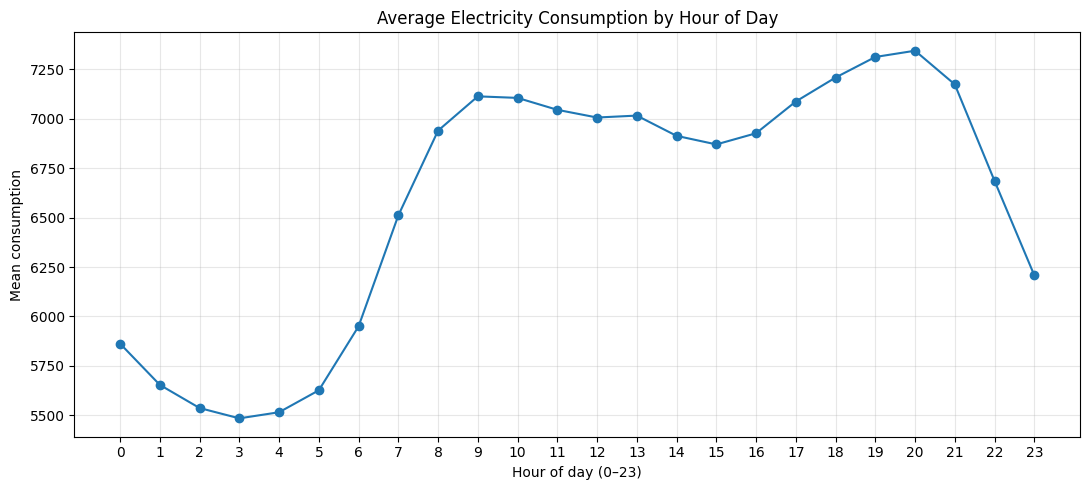

Highest average consumption hour: 20:00
Lowest average consumption hour:  03:00


In [ ]:
df["hour"] = df["DateTime"].dt.hour
hourly_profile = df.groupby("hour")["Consumption"].agg(["mean", "median", "std", "count"])

display(hourly_profile)

plt.figure(figsize=(11, 5))
plt.plot(hourly_profile.index, hourly_profile["mean"], marker="o")
plt.xticks(range(0, 24))
plt.title("Average Electricity Consumption by Hour of Day")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Mean consumption")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

highest_hour = int(hourly_profile["mean"].idxmax())
lowest_hour = int(hourly_profile["mean"].idxmin())
print(f"Highest average consumption hour: {highest_hour:02d}:00")
print(f"Lowest average consumption hour:  {lowest_hour:02d}:00")

##Interpretation

The results show a clear daily pattern in electricity consumption. Average consumption is lowest at **03:00**, at approximately 5,484 units, and highest at **20:00**, at approximately 7,345 units. Consumption gradually decreases during the early morning, reaching its lowest level around 03:00, before rising sharply from 06:00 to 09:00. It remains relatively high throughout much of the day, with another increase during the evening and a peak at 20:00. After 21:00, consumption begins to decline. This pattern suggests that electricity demand varies according to the time of day, making the hour an important feature for further time-series analysis. However, the visualization alone does not establish the reasons for these changes.

## 11. Lag analysis

### Analytical question 3 — Required lagged-feature question
**How strongly is current electricity consumption associated with consumption one hour earlier?**

A lag feature shifts the target so each row contains a previous observation. `Consumption_lag_1` is the prior recorded observation after sorting by timestamp. Because the file contains repeated timestamps, interpret this as the **previous row in time-sorted data**, not as a guaranteed distinct clock hour. We also show how much the lagged correlation is affected by the data structure.

Correlation between consumption and previous-row consumption: 0.9621


,Consumption,Consumption_lag_1
count,"46,010.00","46,010.00"
mean,"6,587.62","6,587.65"
std,"1,043.67","1,043.64"
min,"3,889.00","3,889.00"
25%,"5,773.00","5,773.00"
50%,"6,552.00","6,552.00"
75%,"7,321.00","7,321.00"
max,"9,615.00","9,615.00"


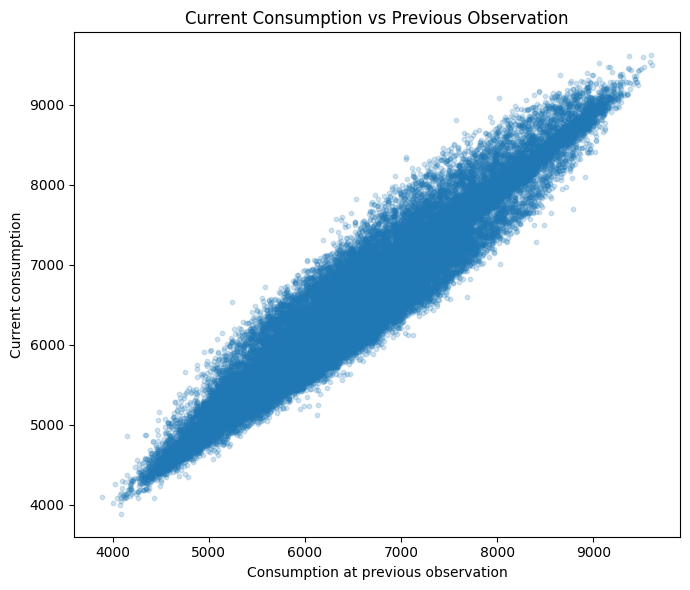

In [ ]:
lag_df = df[["DateTime", "Consumption"]].copy()
lag_df = lag_df.sort_values("DateTime").reset_index(drop=True)
lag_df["Consumption_lag_1"] = lag_df["Consumption"].shift(1)
lag_pairs = lag_df.dropna(subset=["Consumption", "Consumption_lag_1"]).copy()

lag_corr = lag_pairs["Consumption"].corr(lag_pairs["Consumption_lag_1"])
print(f"Correlation between consumption and previous-row consumption: {lag_corr:.4f}")
display(lag_pairs[["Consumption", "Consumption_lag_1"]].describe())

plt.figure(figsize=(7, 6))
plt.scatter(lag_pairs["Consumption_lag_1"], lag_pairs["Consumption"], alpha=0.2, s=10)
plt.title("Current Consumption vs Previous Observation")
plt.xlabel("Consumption at previous observation")
plt.ylabel("Current consumption")
plt.tight_layout()
plt.show()

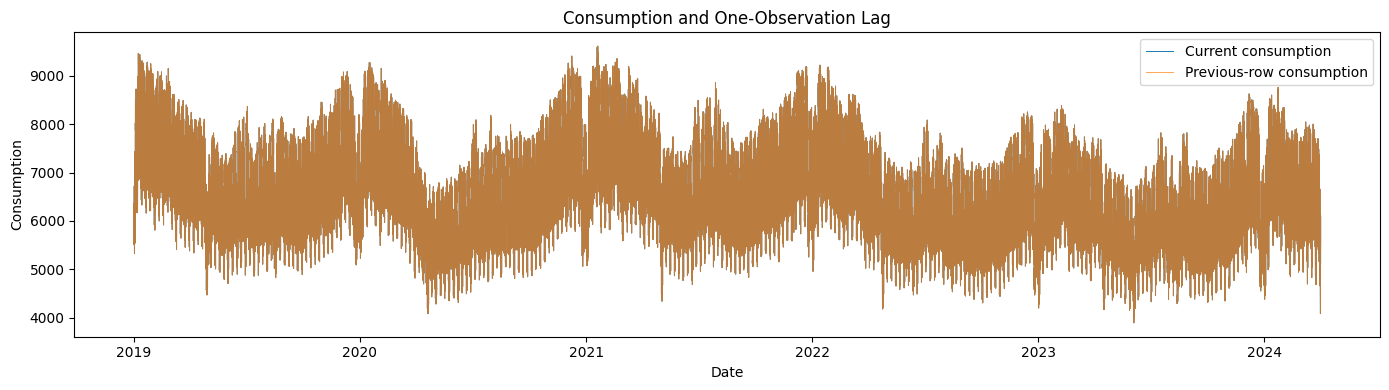

In [ ]:
plt.figure(figsize=(14, 4))
plt.plot(lag_df["DateTime"], lag_df["Consumption"], label="Current consumption", linewidth=0.7)
plt.plot(lag_df["DateTime"], lag_df["Consumption_lag_1"], label="Previous-row consumption", linewidth=0.7, alpha=0.7)
plt.title("Consumption and One-Observation Lag")
plt.xlabel("Date")
plt.ylabel("Consumption")
plt.legend()
plt.tight_layout()
plt.show()

##Interpretation

The correlation between current consumption and the previous recorded observation is **0.9621**, indicating a very strong positive relationship. The scatter plot shows points concentrated around an upward-sloping pattern, meaning that higher consumption in the previous observation is generally associated with higher current consumption, and lower previous consumption is associated with lower current consumption. The two series also follow very similar patterns over time. This suggests that electricity consumption has strong temporal continuity, meaning that recent consumption can provide useful information for understanding the next observation. However, because the dataset contains repeated timestamps, the lag represents the previous recorded row rather than necessarily the previous distinct clock hour. The strong correlation also does not, by itself, establish forecasting accuracy or causation.

## 12. Moving-average analysis

### Analytical question 4 — Required moving-average question
**How does a rolling 24-observation average help reveal changes in electricity consumption?**

A moving average smooths short-term fluctuations. Since the timestamps include repeated clock times and may include gaps, this feature is calculated over **24 consecutive observations**, rather than claiming every window always represents exactly 24 elapsed hours. The rolling window uses current and previous observations; it does not use future values.

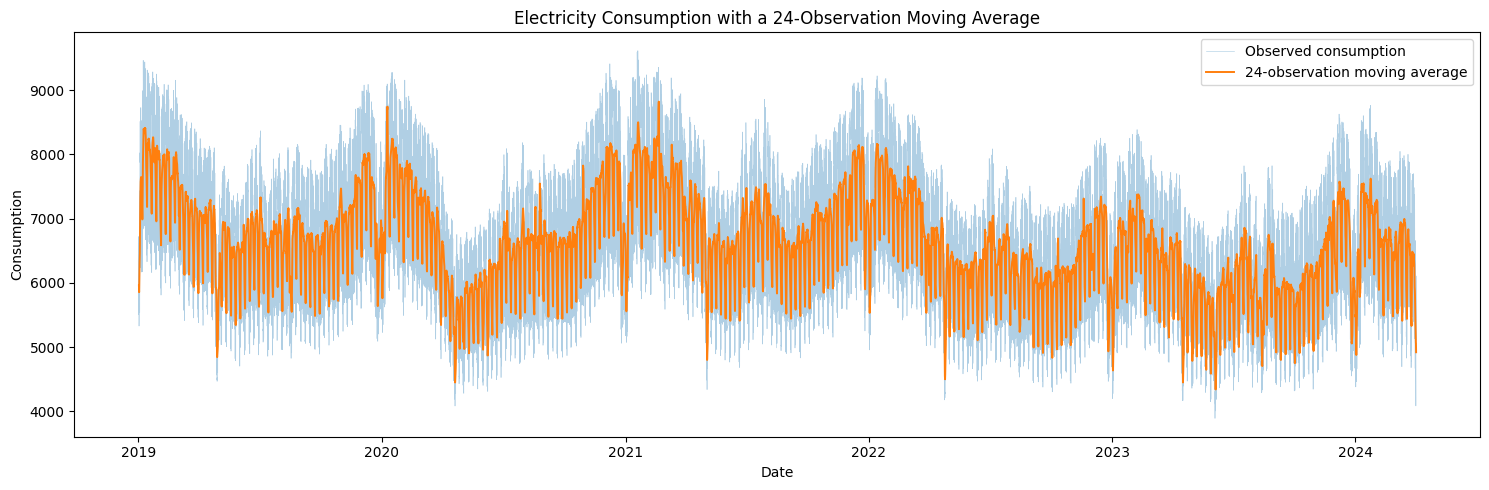

,Consumption,Consumption_MA_24obs
count,"46,011.00","45,988.00"
mean,"6,587.62","6,588.19"
std,"1,043.65",744.47
min,"3,889.00","4,339.42"
25%,"5,773.00","6,062.35"
50%,"6,552.00","6,601.08"
75%,"7,321.00","7,083.72"
max,"9,615.00","8,821.75"


In [ ]:
ma_df = df[["DateTime", "Consumption"]].copy()
ma_df = ma_df.sort_values("DateTime").reset_index(drop=True)
ma_df["Consumption_MA_24obs"] = ma_df["Consumption"].rolling(window=24, min_periods=24).mean()

plt.figure(figsize=(15, 5))
plt.plot(ma_df["DateTime"], ma_df["Consumption"], linewidth=0.45, alpha=0.35, label="Observed consumption")
plt.plot(ma_df["DateTime"], ma_df["Consumption_MA_24obs"], linewidth=1.4, label="24-observation moving average")
plt.title("Electricity Consumption with a 24-Observation Moving Average")
plt.xlabel("Date")
plt.ylabel("Consumption")
plt.legend()
plt.tight_layout()
plt.show()

display(ma_df[["Consumption", "Consumption_MA_24obs"]].describe())

##Interpretation

The visualization shows that the 24-observation moving average smooths short-term fluctuations in electricity consumption, making broader changes easier to identify. The standard deviation decreases from approximately **1,043.65** for the original consumption series to **744.47** for the moving average, demonstrating that the smoothed series varies less. The original consumption reaches a maximum of 9,615 units, while the moving average reaches a lower maximum of approximately 8,821.75 units. Similarly, the moving average minimum is higher than the original minimum, at approximately 4,339.42 compared with 3,889 units. These differences show how averaging reduces the influence of individual peaks and dips while preserving the broader movement of the series. The mean remains almost unchanged, at approximately 6,588 units. Since this calculation uses 24 consecutive observations, it should be interpreted as a 24-observation moving average rather than a guaranteed average of exactly 24 elapsed hours.

## 13. Relationship between production and consumption

### Analytical question 5
**How does reported electricity production relate to electricity consumption?**

This question compares the two reported totals. A strong relationship would show that the series move together, but it would not prove that one directly causes the other. The difference between production and consumption can also be examined descriptively.

Correlation between consumption and production: 0.6951

Production minus consumption summary:


,count,mean,std,min,25%,50%,75%,max
Production_minus_Consumption,"46,011.00",-68.97,794.52,"-2,459.00",-641.00,-132.00,455.00,"3,789.00"


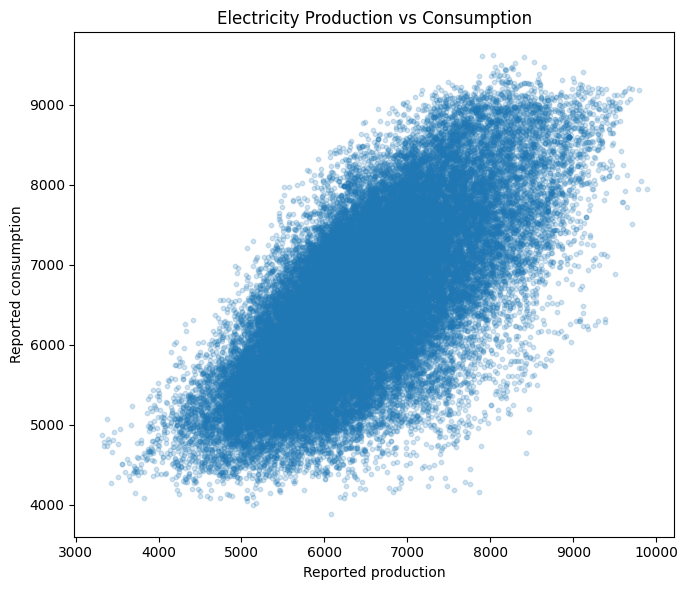

In [ ]:
if "Production" not in df.columns:
    raise ValueError("The dataset does not contain the expected Production column.")

pc = df[["DateTime", "Consumption", "Production"]].dropna().copy()
production_consumption_corr = pc["Consumption"].corr(pc["Production"])
pc["Production_minus_Consumption"] = pc["Production"] - pc["Consumption"]

print(f"Correlation between consumption and production: {production_consumption_corr:.4f}")
print("\nProduction minus consumption summary:")
display(pc["Production_minus_Consumption"].describe().to_frame().T)

plt.figure(figsize=(7, 6))
plt.scatter(pc["Production"], pc["Consumption"], alpha=0.2, s=10)
plt.title("Electricity Production vs Consumption")
plt.xlabel("Reported production")
plt.ylabel("Reported consumption")
plt.tight_layout()
plt.show()

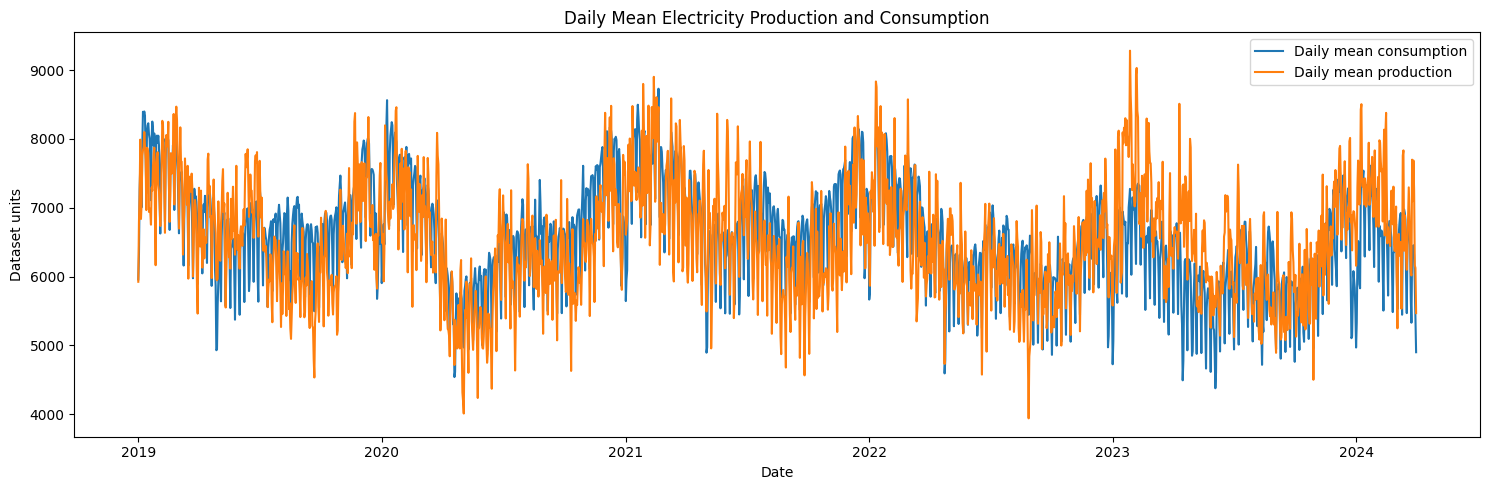

In [ ]:
daily_pc = pc.set_index("DateTime")[["Production", "Consumption"]].resample("D").mean()
plt.figure(figsize=(15, 5))
plt.plot(daily_pc.index, daily_pc["Consumption"], label="Daily mean consumption")
plt.plot(daily_pc.index, daily_pc["Production"], label="Daily mean production")
plt.title("Daily Mean Electricity Production and Consumption")
plt.xlabel("Date")
plt.ylabel("Dataset units")
plt.legend()
plt.tight_layout()
plt.show()

##Interpretation

The results show a positive relationship between electricity production and consumption, with a correlation of **0.6951**. The scatter plot shows that higher production is generally associated with higher consumption, although the points are more widely spread than in the lagged-consumption plot. This indicates that the relationship is positive but not perfect. The daily mean time-series plot also shows that production and consumption often move in similar directions, although their levels sometimes differ.

The difference between production and consumption has a mean of approximately −68.97 units and a median of −132 units. This indicates that the recorded production is slightly lower than consumption on average, although the difference varies considerably over time. The middle 50% of the differences range from −641 to 455 units, while the full range extends from −2,459 to 3,789 units. These variations suggest that production does not always match consumption at each recorded observation. However, the results describe an association and a difference between the recorded totals; they do not establish why the differences occur or prove that production directly causes changes in consumption.

## 14. Energy-generation mix

### Additional analytical question
**How do the recorded generation sources compare over time?**

This is an additional question beyond the minimum five. We compare the available source columns to explore whether their typical levels and patterns differ. Confirm the dataset documentation before treating the columns as directly additive components of total production.

,count,mean,std,min,25%,50%,75%,max
Nuclear,"46,011.00","1,291.18",236.55,562.00,"1,347.00","1,383.00","1,405.00","1,457.00"
Wind,"46,011.00",792.31,675.81,-26.00,236.00,592.00,"1,205.00","2,811.00"
Hydroelectric,"46,011.00","1,857.05",692.59,175.00,"1,347.00","1,747.00","2,265.00","4,434.00"
Oil and Gas,"46,011.00","1,171.89",434.75,198.00,858.00,"1,211.00","1,511.00","2,141.00"
Coal,"46,011.00","1,193.16",320.45,279.00,962.00,"1,172.00","1,406.00","2,537.00"
Solar,"46,011.00",156.69,229.50,0.00,0.00,2.00,280.00,"1,137.00"
Biomass,"46,011.00",55.85,14.24,17.00,45.00,57.00,67.00,89.00


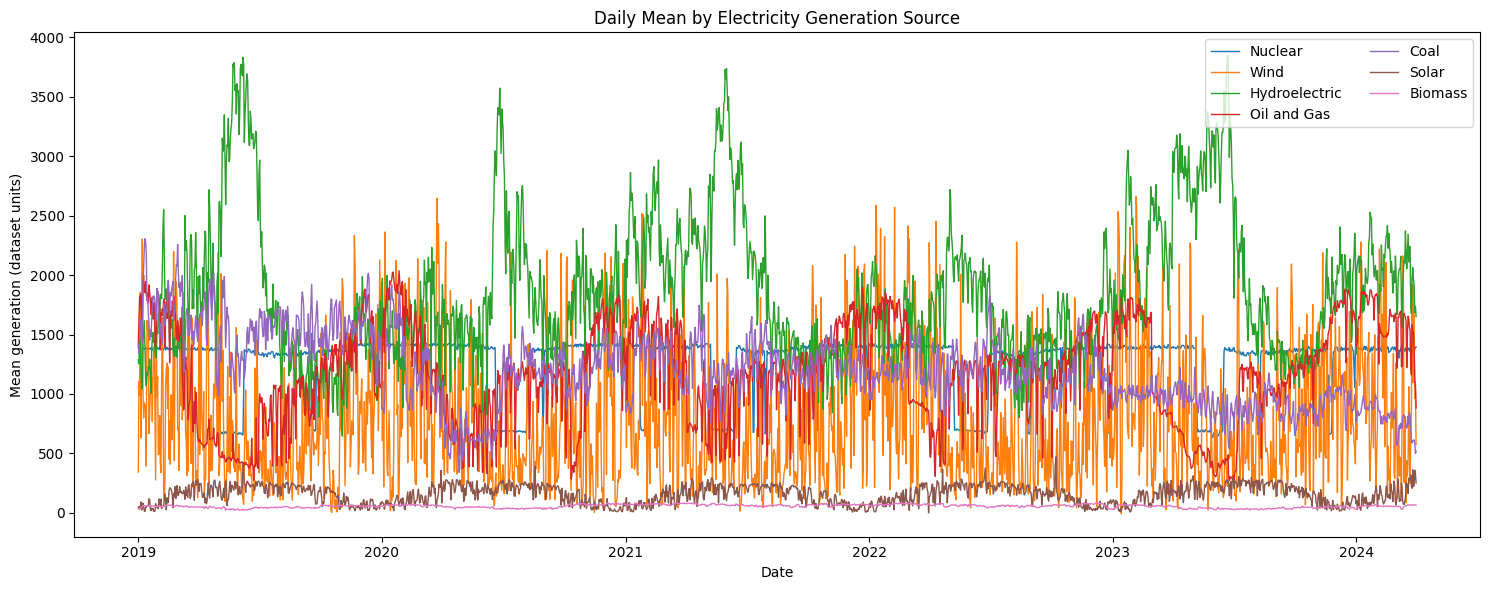

In [ ]:
generation_candidates = [
    "Nuclear", "Wind", "Hydroelectric", "Oil and Gas", "Coal", "Solar", "Biomass"
]
generation_cols = [col for col in generation_candidates if col in df.columns]

if generation_cols:
    display(df[generation_cols].describe().T)

    daily_generation = (
        df.set_index("DateTime")[generation_cols]
          .resample("D")
          .mean()
    )

    plt.figure(figsize=(15, 6))
    for col in generation_cols:
        plt.plot(daily_generation.index, daily_generation[col], label=col, linewidth=1)
    plt.title("Daily Mean by Electricity Generation Source")
    plt.xlabel("Date")
    plt.ylabel("Mean generation (dataset units)")
    plt.legend(ncol=2)
    plt.tight_layout()
    plt.show()
else:
    print("No recognized generation-source columns were found.")

##Interpretation
The numerical distributions show that the different electricity generation sources vary in their typical output and level of variability. Hydroelectric generation has the highest mean among the individual energy sources, at approximately 1,857, followed by nuclear at 1,291, coal at 1,193, and oil and gas at 1,172. Wind generation has a mean of approximately 792, while solar and biomass have much lower means of approximately 157 and 56, respectively.

Wind generation shows substantial variability, with a standard deviation of approximately 676 and values ranging from −26 to 2,811. Its mean is higher than its median of 592, suggesting a right-skewed distribution in which some observations have considerably higher output. Hydroelectric generation also varies considerably, ranging from 175 to 4,434. In comparison, nuclear generation is more concentrated around its median of 1,383, while biomass values are relatively concentrated between the first and third quartiles of 45 and 67.

Solar generation has a particularly uneven distribution. Its median is only 2, its first quartile is zero, and its mean is approximately 157. This indicates that many observations have zero or very low solar output, while some have much higher values. The negative minimum for wind generation should be investigated to understand how it was recorded. Overall, the distributions show that generation sources differ considerably in their output levels and variability, which may be important when analysing the relationship between generation and electricity consumption.



## 15. Correlation overview

This heatmap gives an overview of linear associations among numerical columns. Correlation can help generate hypotheses, but it does not establish causality. Some variables may also be mathematically related (for example, totals and their components), so interpret correlations cautiously.

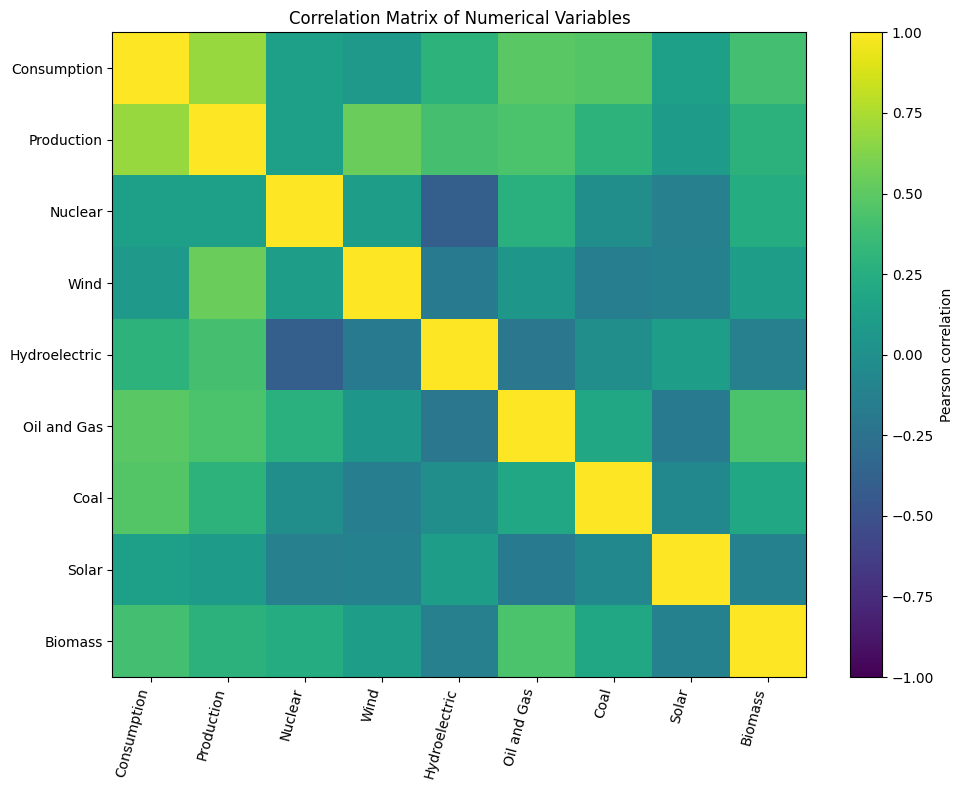

,Consumption,Production,Nuclear,Wind,Hydroelectric,Oil and Gas,Coal,Solar,Biomass
Consumption,1.00,0.70,0.13,0.08,0.29,0.49,0.46,0.13,0.40
Production,0.70,1.00,0.13,0.54,0.41,0.43,0.29,0.10,0.28
Nuclear,0.13,0.13,1.00,0.12,-0.40,0.27,-0.01,-0.13,0.24
Wind,0.08,0.54,0.12,1.00,-0.18,0.06,-0.14,-0.12,0.12
Hydroelectric,0.29,0.41,-0.40,-0.18,1.00,-0.20,-0.01,0.12,-0.13
Oil and Gas,0.49,0.43,0.27,0.06,-0.20,1.00,0.20,-0.19,0.43
Coal,0.46,0.29,-0.01,-0.14,-0.01,0.20,1.00,-0.07,0.19
Solar,0.13,0.10,-0.13,-0.12,0.12,-0.19,-0.07,1.00,-0.12
Biomass,0.40,0.28,0.24,0.12,-0.13,0.43,0.19,-0.12,1.00


In [ ]:
corr_cols = [col for col in numeric_cols if col in df.columns]
corr = df[corr_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=75, ha="right")
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)
ax.set_title("Correlation Matrix of Numerical Variables")
fig.colorbar(image, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

display(corr.round(2))

##Interpretation

The correlation matrix shows the strength and direction of the linear relationships between electricity consumption, total production, and individual generation sources. Electricity consumption has a positive correlation of approximately **0.70 with total production**, indicating that higher production generally occurs alongside higher consumption. Among the individual generation sources, oil and gas has a correlation of approximately 0.49 with consumption, followed by coal at 0.46, biomass at 0.40, and hydroelectric generation at 0.29. Nuclear and solar generation have weaker positive correlations with consumption, both around 0.13, while wind has a correlation of approximately 0.08.

The matrix also shows relationships between the generation sources themselves. Wind generation has a positive correlation of approximately 0.54 with total production, while hydroelectric generation has a correlation of approximately 0.41 with production. Nuclear and hydroelectric generation have a negative correlation of approximately −0.40, indicating that higher values of one tend to be associated with lower values of the other in this dataset. However, this does not establish that one source causes the other to decrease.

Overall, the matrix suggests that total production and consumption tend to move together, but their relationship is not perfect. The individual generation sources have different relationships with consumption and production. These correlations can help identify useful variables for further time-series analysis and forecasting, although correlation alone does not prove causation and may not capture nonlinear relationships.

## 16. Summary of Task 1A and Task 1B

Use this section to prepare the final report after all cells have run.

### Task 1A — Dataset understanding
Summarize:
- the number of observations and variables;
- the date range and observed sampling interval;
- missing-value counts;
- exact duplicate rows and repeated timestamps;
- key descriptive statistics and distribution patterns;
- any data-quality limitations and the decisions taken.

### Task 1B — Analytical questions answered
At minimum, include these five questions and the corresponding visualizations:
1. How has electricity consumption changed over time?
2. At which hours is average electricity consumption highest and lowest?
3. How strongly is current consumption associated with the previous observation? (**lag feature**)
4. How does a 24-observation moving average reveal changes in consumption? (**moving average**)
5. How does reported production relate to consumption?

The generation-mix analysis is an additional question.

### Reporting checklist
- [ ] Every question has at least one visualization.
- [ ] Every visualization is followed by a detailed interpretation based on the actual output.
- [ ] Missing data and duplicate handling are explained and justified.
- [ ] Lag and moving-average features are clearly described.
- [ ] No findings or values are invented.
- [ ] The notebook runs from top to bottom without relying on hidden variables.
- [ ] The final report explains limitations, including repeated timestamps and suspicious values.

### Important note on preprocessing and forecasting
This notebook explores and engineers features for Task 1A and 1B. Before model training, the group should agree on how to handle repeated timestamps and any suspicious values. For forecasting evaluation, split data chronologically into training, validation, and test periods rather than randomly shuffling the time series. Fit any learned preprocessing steps using training data only.

## 17. Task 1C — Preprocessing and feature engineering for forecasting

This section turns the raw data into a model-ready dataset. It continues from `df_raw` (loaded in Section 4) and can be run top to bottom.

**Forecasting setup.** The target is `Consumption` at hour *t*. The model may only use information available up to hour *t − 1*. Production and generation-source columns are therefore used **only as lagged values**, because the current hour's production is not known at forecast time. Calendar features (hour, day, month) are known in advance and are safe to use.

**Pipeline**
1. Investigate repeated timestamps
2. Clean the data (duplicates, negatives, regular hourly index, missing values)
3. Engineer features (lags, moving averages, calendar)
4. Leakage check
5. Chronological train / validation / test split
6. Scale using training data only, and save artifacts for Task 4

In [ ]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

TARGET = "Consumption"
TIME_COL = "DateTime"
FREQ = "h"                    # expected observation frequency (hourly)
MAX_GAP_HOURS = 6             # longest gap we are willing to interpolate
LAGS = [1, 2, 3, 24, 48, 168] # 1-3 hours, 1 day, 2 days, 1 week
ROLL_WINDOWS = [24, 168]      # 1 day, 1 week
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15

# Where to save processed data and the scaler (next to the dataset if known)
OUT_DIR = (DATA_PATH.parent / "processed") if "DATA_PATH" in globals() else Path("processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Artifacts will be saved to:", OUT_DIR)

Artifacts will be saved to: /content/processed


### 17.1 Investigate repeated timestamps before changing anything

Section 6 flagged repeated timestamps. Before deciding how to handle them, check how many there are, whether their values actually differ, and when they occur. If they cluster on the days clocks go back (late March / late October in many countries), they are most likely daylight-saving-time artifacts.

In [ ]:
tmp = df_raw.copy()
tmp[TIME_COL] = pd.to_datetime(tmp[TIME_COL], errors="coerce")
tmp = tmp.dropna(subset=[TIME_COL]).sort_values(TIME_COL)

exact_dups = int(tmp.duplicated().sum())
rep_mask = tmp[TIME_COL].duplicated(keep=False)
rep = tmp[rep_mask]
print(f"Exact duplicate rows: {exact_dups}")
print(f"Rows in repeated-timestamp groups: {len(rep)} "
      f"({rep[TIME_COL].nunique()} distinct timestamps)")

if len(rep):
    num = rep.select_dtypes("number").columns
    spread = rep.groupby(TIME_COL)[num].agg(lambda s: s.max() - s.min())
    n_differ = int((spread.abs().sum(axis=1) > 0).sum())
    print(f"Repeated timestamps whose values differ: {n_differ} of {len(spread)}")
    print("\nRepeated timestamps by month:")
    display(rep.drop_duplicates(TIME_COL)[TIME_COL].dt.to_period("M").value_counts().sort_index().to_frame("count"))
    print("Examples:")
    display(rep.head(10))

Exact duplicate rows: 4
Rows in repeated-timestamp groups: 14 (5 distinct timestamps)
Repeated timestamps whose values differ: 5 of 5

Repeated timestamps by month:


,count
DateTime,
2019-10,1
2020-10,1
2021-10,1
2022-10,1
2023-10,1


Examples:


,DateTime,Consumption,Production,Nuclear,Wind,Hydroelectric,Oil and Gas,Coal,Solar,Biomass
7178,2019-10-27 03:00:00,5186,4478,1373,77,750,696,1532,0,49
7179,2019-10-27 03:00:00,5196,4459,1373,74,725,719,1515,0,50
7180,2019-10-27 03:00:00,5196,4459,1373,74,725,719,1515,0,50
15917,2020-10-25 03:00:00,5220,5412,1418,1188,1098,594,1048,0,65
15915,2020-10-25 03:00:00,5181,5356,1417,1120,1155,566,1034,0,65
15916,2020-10-25 03:00:00,5220,5412,1418,1188,1098,594,1048,0,65
24820,2021-10-31 03:00:00,5351,5265,1414,108,961,1314,1411,0,56
24821,2021-10-31 03:00:00,5341,5258,1415,141,934,1314,1393,0,58
24822,2021-10-31 03:00:00,5341,5258,1415,141,934,1314,1393,0,58
33557,2022-10-30 03:00:00,4475,5266,1385,485,1375,904,1064,0,52


**Decision.** If the repeated timestamps carry different values and no timezone is stored, we cannot tell which record is correct. Instead of arbitrarily keeping one, we **average** the repeated rows so each timestamp has exactly one row. This invents no values and removes no time points. (Exact duplicate rows are simply dropped to one copy.)

### 17.2 Clean the data

`clean_data()` performs these steps and records every change in a report:

| Step | Action | Why |
|---|---|---|
| Timestamps | Parse, drop unparseable, sort | A time series needs a valid ordered time axis |
| Exact duplicates | Keep one copy | They add no information |
| Repeated timestamps | Average numeric values | Cannot tell which record is correct (see above) |
| Negative generation values | Clip to 0 | Physical output cannot be negative; the values are tiny (e.g. wind minimum −26). Clipping keeps the row so the time axis is unbroken |
| Regular hourly index | Insert missing hours as NaN rows | Makes "lag 24" mean exactly 24 hours |
| Short gaps (≤ 6 h) | Time-based linear interpolation | Demand changes smoothly hour to hour |
| Long gaps (> 6 h) | Left as NaN, rows later dropped | Filling days of data would invent it |

In [ ]:
def _fill_short_gaps(df, max_gap_hours):
    """Interpolate only gaps that are <= max_gap_hours long IN FULL.
    (pandas' limit= would half-fill longer gaps, which we do not want.)"""
    filled = df.interpolate(method="time", limit_area="inside")
    for col in df.columns:
        na = df[col].isna()
        run_id = (~na).cumsum()                         # label each run of consecutive NaNs
        run_len = na.groupby(run_id).transform("sum")
        filled.loc[na & (run_len > max_gap_hours), col] = np.nan
    return filled


def clean_data(df_raw, freq=FREQ, max_gap_hours=MAX_GAP_HOURS):
    """Return a cleaned hourly DataFrame indexed by DateTime and a report dict."""
    report = {"rows_raw": int(len(df_raw))}
    df = df_raw.copy()
    df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed")]  # stray index columns

    df[TIME_COL] = pd.to_datetime(df[TIME_COL], errors="coerce")
    report["invalid_timestamps_dropped"] = int(df[TIME_COL].isna().sum())
    df = df.dropna(subset=[TIME_COL]).sort_values(TIME_COL)

    report["exact_duplicates_dropped"] = int(df.duplicated().sum())
    df = df.drop_duplicates()

    num_cols = df.select_dtypes("number").columns.tolist()
    report["repeated_timestamps_collapsed"] = int(df[TIME_COL].duplicated().sum())
    df = df.groupby(TIME_COL)[num_cols].mean()

    gen_cols = [c for c in num_cols if c != TARGET]
    neg = (df[gen_cols] < 0).sum()
    report["negative_values_clipped"] = {c: int(n) for c, n in neg.items() if n}
    df[gen_cols] = df[gen_cols].clip(lower=0)

    full_index = pd.date_range(df.index.min(), df.index.max(), freq=freq, name=TIME_COL)
    report["off_grid_timestamps_dropped"] = int(len(df.index.difference(full_index)))
    report["missing_timestamps_inserted"] = int(len(full_index.difference(df.index)))
    df = df.reindex(full_index)

    report["nan_before_fill"] = {c: int(n) for c, n in df.isna().sum().items() if n}
    df = _fill_short_gaps(df, max_gap_hours)
    report["nan_after_fill"] = {c: int(n) for c, n in df.isna().sum().items() if n}

    report.update(rows_clean=int(len(df)), start=str(df.index.min()), end=str(df.index.max()))
    return df, report


df_clean, clean_report = clean_data(df_raw)
display(pd.Series(clean_report, name="value").to_frame())

,value
rows_raw,46011
invalid_timestamps_dropped,0
exact_duplicates_dropped,4
repeated_timestamps_collapsed,5
negative_values_clipped,{'Wind': 499}
off_grid_timestamps_dropped,0
missing_timestamps_inserted,6
nan_before_fill,"{'Consumption': 6, 'Production': 6, 'Nuclear':..."
nan_after_fill,{}
rows_clean,46008


Unique gaps between consecutive rows: <TimedeltaArray>
['0 days 01:00:00']
Length: 1, dtype: timedelta64[ns]
Duplicate timestamps remaining: 0
Negative values remaining: 0

Missing values remaining per column:


,missing
Consumption,0
Production,0
Nuclear,0
Wind,0
Hydroelectric,0
Oil and Gas,0
Coal,0
Solar,0
Biomass,0


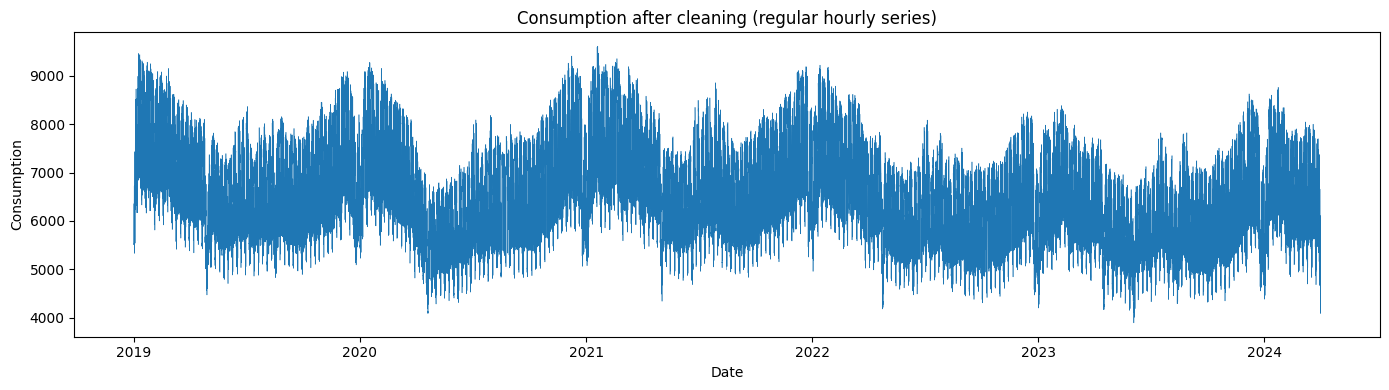

In [ ]:
# Verify the result is a regular hourly series
diffs = df_clean.index.to_series().diff().dropna()
print("Unique gaps between consecutive rows:", diffs.unique())
print("Duplicate timestamps remaining:", int(df_clean.index.duplicated().sum()))
print("Negative values remaining:", int((df_clean < 0).sum().sum()))
print("\nMissing values remaining per column:")
display(df_clean.isna().sum().to_frame("missing"))

# Show where unfilled gaps (if any) are
still_missing = df_clean[df_clean[TARGET].isna()]
if len(still_missing):
    print(f"\n{len(still_missing)} hours of {TARGET} are still missing (gaps longer than {MAX_GAP_HOURS} h):")
    display(still_missing.index.to_series().dt.date.value_counts().sort_index().head(20).to_frame("hours"))

# Compare distribution before vs after cleaning
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df_clean.index, df_clean[TARGET], linewidth=0.4)
ax.set_title("Consumption after cleaning (regular hourly series)")
ax.set_xlabel("Date"); ax.set_ylabel("Consumption")
plt.tight_layout(); plt.show()

In [ ]:
df_clean.reset_index().to_csv("Electricity_cleaned.csv", index=False)

In [ ]:
def add_features(df, drop_na=True):
    """Build model features from the cleaned hourly DataFrame (leakage-safe)."""
    out = pd.DataFrame(index=df.index)
    out[TARGET] = df[TARGET]

    for lag in LAGS:
        out[f"{TARGET}_lag_{lag}"] = df[TARGET].shift(lag)

    past = df[TARGET].shift(1)           # exclude the current value from windows
    for w in ROLL_WINDOWS:
        out[f"{TARGET}_ma_{w}"] = past.rolling(w, min_periods=w).mean()
        out[f"{TARGET}_std_{w}"] = past.rolling(w, min_periods=w).std()

    for c in [c for c in df.columns if c != TARGET]:
        out[f"{c}_lag_1"] = df[c].shift(1)

    idx = df.index
    out["hour"] = idx.hour
    out["dayofweek"] = idx.dayofweek
    out["month"] = idx.month
    out["is_weekend"] = (idx.dayofweek >= 5).astype(int)
    out["hour_sin"] = np.sin(2 * np.pi * idx.hour / 24)
    out["hour_cos"] = np.cos(2 * np.pi * idx.hour / 24)
    out["dow_sin"] = np.sin(2 * np.pi * idx.dayofweek / 7)
    out["dow_cos"] = np.cos(2 * np.pi * idx.dayofweek / 7)
    out["month_sin"] = np.sin(2 * np.pi * (idx.month - 1) / 12)
    out["month_cos"] = np.cos(2 * np.pi * (idx.month - 1) / 12)

    return out.dropna() if drop_na else out


features_all = add_features(df_clean, drop_na=False)
feats = features_all.dropna()
print(f"Rows before dropping NaN: {len(features_all):,}  |  after: {len(feats):,}")
print(f"Rows lost to lag/rolling warm-up and unfilled gaps: {len(features_all) - len(feats):,}")
print(f"Number of features: {feats.shape[1] - 1}")
display(feats.head())

Rows before dropping NaN: 46,008  |  after: 45,840
Rows lost to lag/rolling warm-up and unfilled gaps: 168
Number of features: 28


,Consumption,Consumption_lag_1,Consumption_lag_2,Consumption_lag_3,Consumption_lag_24,Consumption_lag_48,Consumption_lag_168,Consumption_ma_24,Consumption_std_24,Consumption_ma_168,Consumption_std_168,Production_lag_1,Nuclear_lag_1,Wind_lag_1,Hydroelectric_lag_1,Oil and Gas_lag_1,Coal_lag_1,Solar_lag_1,Biomass_lag_1,hour,dayofweek,month,is_weekend,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos
DateTime,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2019-01-08 00:00:00,"7,106.00","7,369.00","7,859.00","8,501.00","6,512.00","6,665.00","6,352.00","7,883.08","1,027.41","7,062.51","1,011.36","7,331.00","1,386.00","2,200.00",731.00,"1,512.00","1,448.00",0.00,54.00,0,1,1,0,0.00,1.00,0.78,0.62,0.00,1.00
2019-01-08 01:00:00,"6,951.00","7,106.00","7,369.00","7,859.00","6,270.00","6,441.00","6,116.00","7,907.83",999.73,"7,067.00","1,009.86","7,352.00","1,384.00","1,988.00",976.00,"1,524.00","1,427.00",0.00,53.00,1,1,1,0,0.26,0.97,0.78,0.62,0.00,1.00
2019-01-08 02:00:00,"6,890.00","6,951.00","7,106.00","7,369.00","6,172.00","6,297.00","5,873.00","7,936.21",960.10,"7,071.97","1,007.20","7,593.00","1,387.00","1,987.00",907.00,"1,716.00","1,540.00",0.00,55.00,2,1,1,0,0.50,0.87,0.78,0.62,0.00,1.00
2019-01-08 03:00:00,"6,839.00","6,890.00","6,951.00","7,106.00","6,228.00","6,168.00","5,682.00","7,966.12",912.76,"7,078.02","1,003.00","7,726.00","1,392.00","1,848.00",851.00,"1,866.00","1,710.00",0.00,57.00,3,1,1,0,0.71,0.71,0.78,0.62,0.00,1.00
2019-01-08 04:00:00,"6,890.00","6,839.00","6,890.00","6,951.00","6,280.00","6,260.00","5,557.00","7,991.58",869.67,"7,084.91",997.31,"7,602.00","1,393.00","1,573.00",902.00,"1,856.00","1,820.00",0.00,57.00,4,1,1,0,0.87,0.50,0.78,0.62,0.00,1.00


In [ ]:
t = feats.index[len(feats) // 2]            # a row in the middle of the data
row = feats.loc[t]
hist = df_clean[TARGET]

for lag in LAGS:
    assert np.isclose(row[f"{TARGET}_lag_{lag}"], hist.loc[t - pd.Timedelta(hours=lag)]), f"lag {lag} mismatch"

for w in ROLL_WINDOWS:
    window = hist.loc[t - pd.Timedelta(hours=w): t - pd.Timedelta(hours=1)]   # ends at t-1, excludes t
    assert len(window) == w
    assert np.isclose(row[f"{TARGET}_ma_{w}"], window.mean()), f"MA {w} mismatch"

assert np.isclose(row["Production_lag_1"], df_clean["Production"].loc[t - pd.Timedelta(hours=1)]) \
    if "Production" in df_clean.columns else True

print(f"Leakage check passed for timestamp {t}:")
print(f"  target now              = {row[TARGET]:,.1f}")
print(f"  lag_1 (t-1h)            = {row[f'{TARGET}_lag_1']:,.1f}")
print(f"  lag_24 (t-24h)          = {row[f'{TARGET}_lag_24']:,.1f}")
print(f"  24h moving avg (t-24..t-1) = {row[f'{TARGET}_ma_24']:,.1f}")

Leakage check passed for timestamp 2021-08-20 00:00:00:
  target now              = 5,851.0
  lag_1 (t-1h)            = 6,295.0
  lag_24 (t-24h)          = 5,715.0
  24h moving avg (t-24..t-1) = 6,580.3


,rows,start,end
train,32087,2019-01-08 00:00:00,2022-09-05 22:00:00
validation,6877,2022-09-05 23:00:00,2023-06-19 11:00:00
test,6876,2023-06-19 12:00:00,2024-03-31 23:00:00


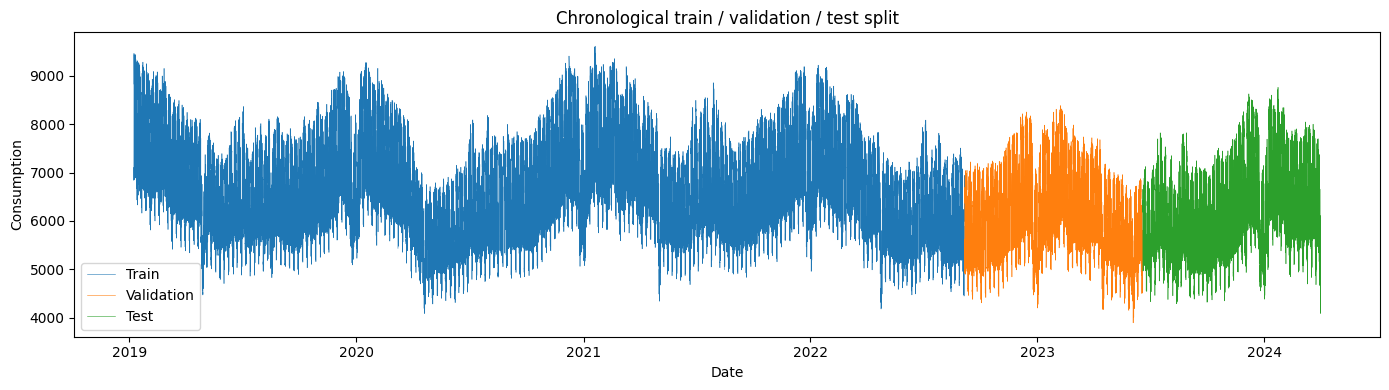

X_train: (32087, 28) | X_val: (6877, 28) | X_test: (6876, 28)


In [ ]:
def chronological_split(df, train_frac=TRAIN_FRAC, val_frac=VAL_FRAC):
    n = len(df)
    i_tr, i_va = int(n * train_frac), int(n * (train_frac + val_frac))
    return df.iloc[:i_tr], df.iloc[i_tr:i_va], df.iloc[i_va:]

train, val, test = chronological_split(feats)

split_table = pd.DataFrame({
    "rows": [len(train), len(val), len(test)],
    "start": [train.index.min(), val.index.min(), test.index.min()],
    "end": [train.index.max(), val.index.max(), test.index.max()],
}, index=["train", "validation", "test"])
display(split_table)

assert train.index.max() < val.index.min() and val.index.max() < test.index.min()

fig, ax = plt.subplots(figsize=(14, 4))
for part, name in [(train, "Train"), (val, "Validation"), (test, "Test")]:
    ax.plot(part.index, part[TARGET], linewidth=0.4, label=name)
ax.set_title("Chronological train / validation / test split")
ax.set_xlabel("Date"); ax.set_ylabel("Consumption"); ax.legend()
plt.tight_layout(); plt.show()

X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
X_val,   y_val   = val.drop(columns=[TARGET]),   val[TARGET]
X_test,  y_test  = test.drop(columns=[TARGET]),  test[TARGET]
print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)

18. Task 1C — Model training, hyperparameter tuning and experiments

In [ ]:
import time
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
from sklearn.inspection import permutation_importance
import joblib

RANDOM_STATE = 42
tscv = TimeSeriesSplit(n_splits=4)

def evaluate(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAPE_%": float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100),
        "R2": r2_score(y_true, y_pred),
    }

def cv_rmse(est, X, y):
    """Mean RMSE over time-ordered CV folds on the training set."""
    return -cross_val_score(est, X, y, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1).mean()

all_features = list(X_train.columns)
exog_features = [c for c in all_features if c.endswith("_lag_1") and not c.startswith(TARGET)]
no_exog_features = [c for c in all_features if c not in exog_features]
print(f"{len(all_features)} features in total; {len(exog_features)} are lagged production/generation columns:")
print(exog_features)

results, fitted = [], {}

def record(name, model, params, features, cv_score, est=None):
    """Fit on train, score on validation, and store one row of the experiment table."""
    if est is not None:
        est.fit(X_train[features], y_train)
        pred = est.predict(X_val[features])
        fitted[name] = (est, features)
    else:
        pred = X_val[features[0]].values          # baselines: copy a lag column
    m = evaluate(y_val, pred)
    results.append({"Experiment": name, "Model": model, "Features": len(features) if est is not None else "-",
                    "Hyperparameters": params, "CV RMSE": cv_score,
                    "Val MAE": m["MAE"], "Val RMSE": m["RMSE"], "Val MAPE %": m["MAPE_%"], "Val R2": m["R2"]})
    return pred

# ---------- Baselines (no training) ----------
record("B1 Persistence (t-1h)",   "Baseline", "prediction = Consumption_lag_1",   [f"{TARGET}_lag_1"],   np.nan)
record("B2 Seasonal naive (t-24h)", "Baseline", "prediction = Consumption_lag_24",  [f"{TARGET}_lag_24"],  np.nan)
record("B3 Weekly naive (t-168h)", "Baseline", "prediction = Consumption_lag_168", [f"{TARGET}_lag_168"], np.nan)
display(pd.DataFrame(results)[["Experiment", "Val MAE", "Val RMSE", "Val MAPE %", "Val R2"]].round(3))

28 features in total; 8 are lagged production/generation columns:
['Production_lag_1', 'Nuclear_lag_1', 'Wind_lag_1', 'Hydroelectric_lag_1', 'Oil and Gas_lag_1', 'Coal_lag_1', 'Solar_lag_1', 'Biomass_lag_1']


,Experiment,Val MAE,Val RMSE,Val MAPE %,Val R2
0,B1 Persistence (t-1h),202.32,274.87,3.29,0.91
1,B2 Seasonal naive (t-24h),409.00,598.86,6.79,0.58
2,B3 Weekly naive (t-168h),319.84,474.64,5.29,0.74


In [ ]:
# Experiment 1: Ridge, default alpha
ridge_default = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
record("E1 Ridge (default)", "Ridge", "alpha=1.0", all_features,
       cv_rmse(ridge_default, X_train[all_features], y_train), est=ridge_default)

# Experiment 2: Ridge, tuned alpha
t0 = time.time()
ridge_search = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    param_grid={"ridge__alpha": np.logspace(-3, 3, 13)},
    cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1)
ridge_search.fit(X_train[all_features], y_train)
print(f"Ridge grid search finished in {time.time() - t0:.1f}s")
print("Best params:", ridge_search.best_params_)

record("E2 Ridge (tuned)", "Ridge", f"alpha={ridge_search.best_params_['ridge__alpha']:.4g}", all_features,
       -ridge_search.best_score_, est=ridge_search.best_estimator_)

display(pd.DataFrame(ridge_search.cv_results_)[["param_ridge__alpha", "mean_test_score"]]
        .assign(CV_RMSE=lambda d: -d["mean_test_score"]).drop(columns="mean_test_score").round(2))

Ridge grid search finished in 1.6s
Best params: {'ridge__alpha': np.float64(0.03162277660168379)}


,param_ridge__alpha,CV_RMSE
0,0.00,154.91
1,0.00,154.90
2,0.01,154.90
3,0.03,154.89
4,0.10,154.90
5,0.32,154.92
6,1.00,155.00
7,3.16,155.26
8,10.00,156.16
9,31.62,159.10


In [ ]:
# Experiment 3: Gradient boosting, defaults
hgb_default = HistGradientBoostingRegressor(random_state=RANDOM_STATE)
record("E3 HistGB (default)", "HistGradientBoosting", "library defaults", all_features,
       cv_rmse(hgb_default, X_train[all_features], y_train), est=hgb_default)

# Experiment 4: Gradient boosting, tuned
param_dist = {
    "learning_rate": [0.03, 0.05, 0.1],
    "max_iter": [200, 400, 600],
    "max_depth": [None, 4, 6, 8],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [20, 50, 100],
    "l2_regularization": [0, 0.1, 1],
}
t0 = time.time()
hgb_search = RandomizedSearchCV(
    HistGradientBoostingRegressor(random_state=RANDOM_STATE),
    param_distributions=param_dist, n_iter=20, cv=tscv,
    scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=-1)
hgb_search.fit(X_train[all_features], y_train)
print(f"HistGB randomised search finished in {time.time() - t0:.1f}s")
print("Best params:", hgb_search.best_params_)

record("E4 HistGB (tuned)", "HistGradientBoosting", str(hgb_search.best_params_), all_features,
       -hgb_search.best_score_, est=hgb_search.best_estimator_)

cols = ["rank_test_score", "mean_test_score"] + [f"param_{k}" for k in param_dist]
top5 = (pd.DataFrame(hgb_search.cv_results_)[cols].sort_values("rank_test_score").head(5)
        .assign(CV_RMSE=lambda d: -d["mean_test_score"]).drop(columns="mean_test_score"))
print("\nTop 5 parameter combinations (by CV RMSE):")
display(top5.round(2))

HistGB randomised search finished in 131.5s
Best params: {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'max_iter': 600, 'max_depth': 8, 'learning_rate': 0.05, 'l2_regularization': 1}

Top 5 parameter combinations (by CV RMSE):


,rank_test_score,param_learning_rate,param_max_iter,param_max_depth,param_max_leaf_nodes,param_min_samples_leaf,param_l2_regularization,CV_RMSE
2,1,0.05,600,8,15,20,1.00,107.90
5,2,0.05,600,8,31,50,0.10,108.19
19,3,0.10,400,8,15,50,0.00,108.20
18,4,0.05,600,4,15,20,1.00,108.78
13,5,0.05,600,4,15,50,0.10,108.87


In [ ]:
abl_params = {k: v for k, v in hgb_search.best_params_.items()}
hgb_noexog = HistGradientBoostingRegressor(random_state=RANDOM_STATE, **abl_params)
record("E5 HistGB tuned, no exogenous", "HistGradientBoosting", "tuned params; consumption + calendar features only",
       no_exog_features, cv_rmse(hgb_noexog, X_train[no_exog_features], y_train), est=hgb_noexog)
print("Done. Features used:", len(no_exog_features))

Done. Features used: 20


,Experiment,Model,Features,Hyperparameters,CV RMSE,Val MAE,Val RMSE,Val MAPE %,Val R2
0,B1 Persistence (t-1h),Baseline,-,prediction = Consumption_lag_1,NaN,202.32,274.87,3.29,0.91
1,B2 Seasonal naive (t-24h),Baseline,-,prediction = Consumption_lag_24,NaN,409.00,598.86,6.79,0.58
2,B3 Weekly naive (t-168h),Baseline,-,prediction = Consumption_lag_168,NaN,319.84,474.64,5.29,0.74
3,E1 Ridge (default),Ridge,28,alpha=1.0,155.00,108.85,145.21,1.78,0.97
4,E2 Ridge (tuned),Ridge,28,alpha=0.03162,154.89,112.84,151.31,1.85,0.97
5,E3 HistGB (default),HistGradientBoosting,28,library defaults,111.36,86.98,118.26,1.43,0.98
6,E4 HistGB (tuned),HistGradientBoosting,28,"{'min_samples_leaf': 20, 'max_leaf_nodes': 15,...",107.90,85.77,116.06,1.41,0.98
7,"E5 HistGB tuned, no exogenous",HistGradientBoosting,20,tuned params; consumption + calendar features ...,111.02,88.23,119.50,1.45,0.98


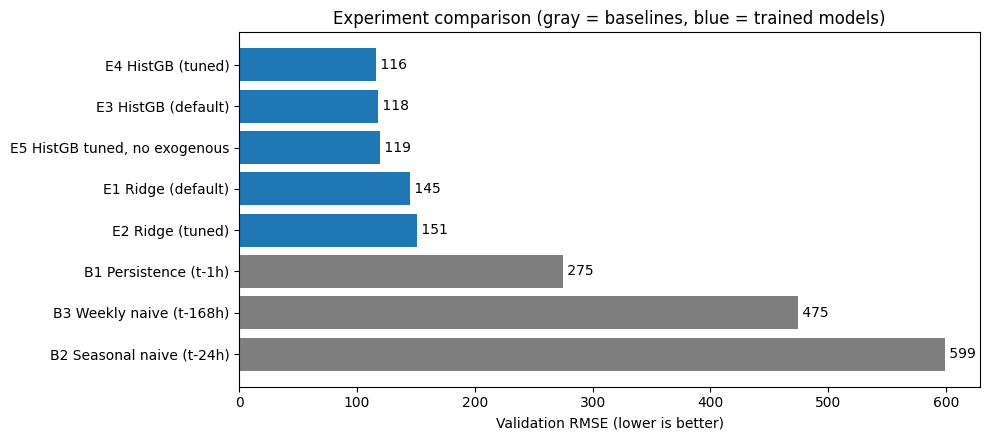

In [ ]:
exp_table = pd.DataFrame(results)
display(exp_table.round(3))

# Chart: validation RMSE for every experiment
plot_df = exp_table.sort_values("Val RMSE", ascending=False)
colors = ["tab:gray" if m == "Baseline" else "tab:blue" for m in plot_df["Model"]]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(plot_df["Experiment"], plot_df["Val RMSE"], color=colors)
ax.set_xlabel("Validation RMSE (lower is better)")
ax.set_title("Experiment comparison (gray = baselines, blue = trained models)")
for y, v in enumerate(plot_df["Val RMSE"]):
    ax.text(v, y, f" {v:,.0f}", va="center")
plt.tight_layout(); plt.show()

In [ ]:
trained = exp_table[exp_table["Model"] != "Baseline"]
best_name = trained.loc[trained["Val RMSE"].idxmin(), "Experiment"]
best_est, best_features = fitted[best_name]
print("Selected model:", best_name)

# Refit on train + validation, evaluate once on test
X_trval = pd.concat([X_train, X_val])[best_features]
y_trval = pd.concat([y_train, y_val])
final_model = clone(best_est).fit(X_trval, y_trval)
test_pred = pd.Series(final_model.predict(X_test[best_features]), index=X_test.index, name="prediction")

rows = []
for label, col in [("B1 Persistence (t-1h)", f"{TARGET}_lag_1"),
                   ("B2 Seasonal naive (t-24h)", f"{TARGET}_lag_24"),
                   ("B3 Weekly naive (t-168h)", f"{TARGET}_lag_168")]:
    rows.append({"Model": label, **evaluate(y_test, X_test[col])})
rows.append({"Model": f"FINAL: {best_name}", **evaluate(y_test, test_pred)})
test_table = pd.DataFrame(rows).set_index("Model")
display(test_table.round(3))

# Save for Task 4 (the pipeline expects features in this exact order)
joblib.dump({"model": final_model, "features": best_features, "target": TARGET,
             "lags": LAGS, "roll_windows": ROLL_WINDOWS}, OUT_DIR / "best_model.joblib")
(OUT_DIR / "model_metadata.json").write_text(json.dumps({
    "selected_experiment": best_name,
    "features": best_features,
    "trained_on_through": str(X_val.index.max()),
    "test_metrics": test_table.loc[f"FINAL: {best_name}"].to_dict(),
}, indent=2))
print("\nSaved model to", OUT_DIR / "best_model.joblib")

Selected model: E4 HistGB (tuned)


,MAE,RMSE,MAPE_%,R2
Model,,,,
B1 Persistence (t-1h),216.68,285.22,3.48,0.91
B2 Seasonal naive (t-24h),404.15,586.55,6.57,0.62
B3 Weekly naive (t-168h),343.38,516.61,5.50,0.70
FINAL: E4 HistGB (tuned),84.44,112.86,1.36,0.99



Saved model to /content/processed/best_model.joblib


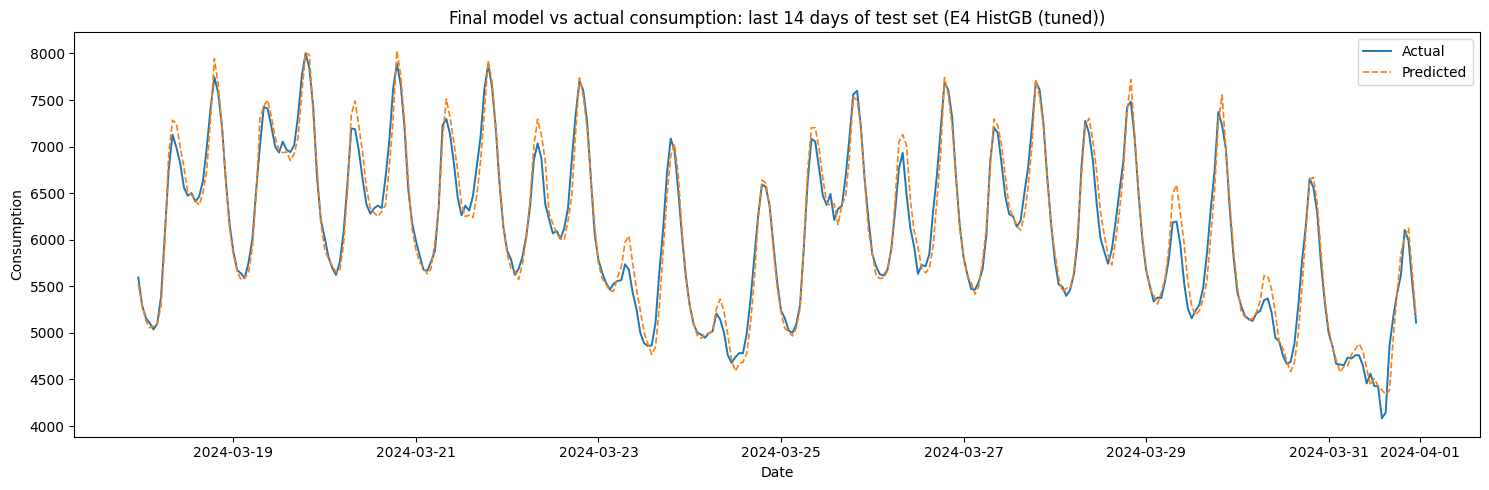

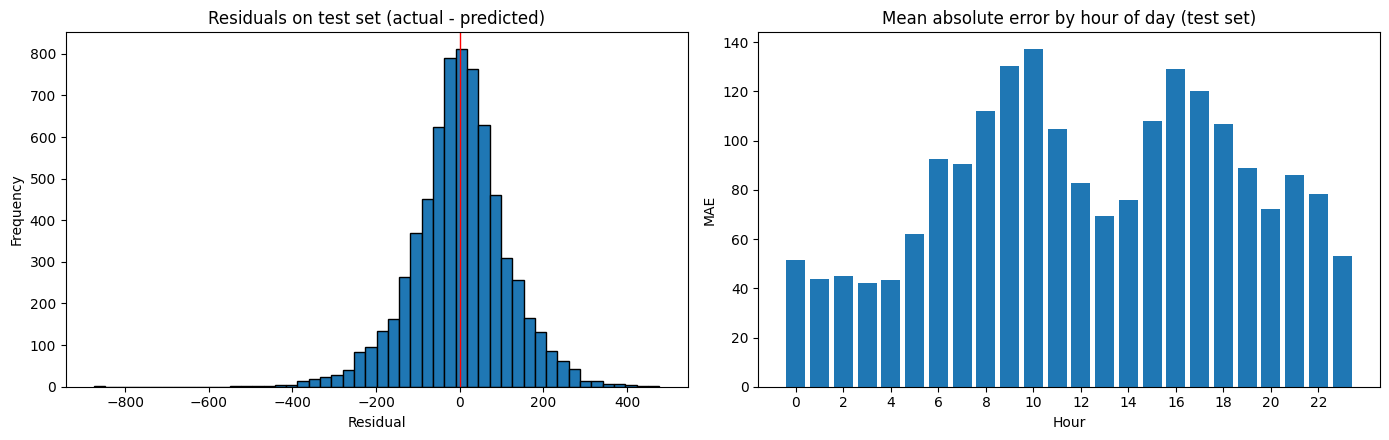

Mean residual (bias): -0.85  |  Std of residuals: 112.86
Hardest hour: 10:00 (MAE 137.2)   Easiest hour: 03:00 (MAE 42.1)


In [ ]:
# Forecast vs actual: last 14 days of the test set
window = slice(test_pred.index.max() - pd.Timedelta(days=14), None)
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(y_test.loc[window].index, y_test.loc[window], label="Actual", linewidth=1.4)
ax.plot(test_pred.loc[window].index, test_pred.loc[window], label="Predicted", linewidth=1.2, linestyle="--")
ax.set_title(f"Final model vs actual consumption: last 14 days of test set ({best_name})")
ax.set_xlabel("Date"); ax.set_ylabel("Consumption"); ax.legend()
plt.tight_layout(); plt.show()

# Residual analysis
resid = y_test - test_pred
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(resid, bins=50, edgecolor="black")
axes[0].axvline(0, color="red", linewidth=1)
axes[0].set_title("Residuals on test set (actual - predicted)")
axes[0].set_xlabel("Residual"); axes[0].set_ylabel("Frequency")

mae_by_hour = resid.abs().groupby(resid.index.hour).mean()
axes[1].bar(mae_by_hour.index, mae_by_hour.values)
axes[1].set_title("Mean absolute error by hour of day (test set)")
axes[1].set_xlabel("Hour"); axes[1].set_ylabel("MAE"); axes[1].set_xticks(range(0, 24, 2))
plt.tight_layout(); plt.show()

print(f"Mean residual (bias): {resid.mean():,.2f}  |  Std of residuals: {resid.std():,.2f}")
print(f"Hardest hour: {mae_by_hour.idxmax():02d}:00 (MAE {mae_by_hour.max():,.1f})   "
      f"Easiest hour: {mae_by_hour.idxmin():02d}:00 (MAE {mae_by_hour.min():,.1f})")

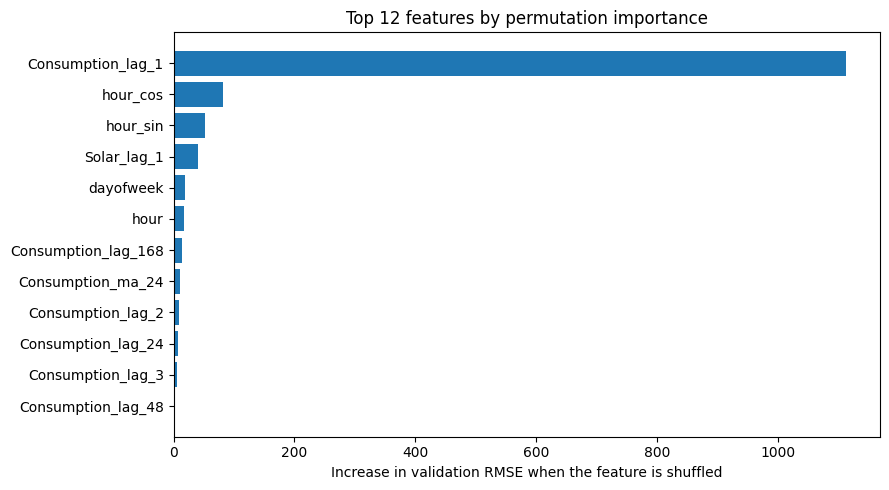

,importance
Consumption_lag_1,"1,113.09"
hour_cos,81.51
hour_sin,51.86
Solar_lag_1,41.17
dayofweek,19.30
hour,16.54
Consumption_lag_168,14.07
Consumption_ma_24,10.42
Consumption_lag_2,8.31
Consumption_lag_24,7.99


In [ ]:
# Which features matter? Permutation importance on the VALIDATION set,
# using the model fitted on the training set only (the test set stays untouched).
imp_model, imp_feats = fitted[best_name]
pi = permutation_importance(imp_model, X_val[imp_feats], y_val, n_repeats=5,
                            scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=imp_feats).sort_values(ascending=False)

top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top.index, top.values)
ax.set_xlabel("Increase in validation RMSE when the feature is shuffled")
ax.set_title("Top 12 features by permutation importance")
plt.tight_layout(); plt.show()
display(imp.head(12).round(2).to_frame("importance"))

In [ ]:
# Auto-generated summary of the numbers above (use as a starting point for the report)
final = test_table.loc[f"FINAL: {best_name}"]
base_rows = test_table[test_table.index.str.startswith("B")]
best_base = base_rows["RMSE"].idxmin()
gain = 100 * (base_rows.loc[best_base, "RMSE"] - final["RMSE"]) / base_rows.loc[best_base, "RMSE"]

print(f"Selected model: {best_name}")
print(f"Test RMSE {final['RMSE']:,.1f} | MAE {final['MAE']:,.1f} | MAPE {final['MAPE_%']:.2f}% | R2 {final['R2']:.3f}")
print(f"Strongest baseline on test: {best_base} (RMSE {base_rows.loc[best_base, 'RMSE']:,.1f})")
print(f"Improvement over that baseline: {gain:.1f}% lower RMSE")
print(f"Top 3 features by permutation importance: {', '.join(imp.index[:3])}")

Selected model: E4 HistGB (tuned)
Test RMSE 112.9 | MAE 84.4 | MAPE 1.36% | R2 0.986
Strongest baseline on test: B1 Persistence (t-1h) (RMSE 285.2)
Improvement over that baseline: 60.4% lower RMSE
Top 3 features by permutation importance: Consumption_lag_1, hour_cos, hour_sin
